In [7]:
from typing import ClassVar

"""
Microsimulation of the New Zealand population using Vivarium-core

This script sets up a simple agent-based microsimulation of the NZ population,
including aging and mortality based on publicly available Stats NZ
population estimates and life table hazards.

Prerequisites:
    pip install vivarium-core pandas numpy

Data sources (public URLs):
  - Population estimates at year end: Stats NZ CSV
    https://www.stats.govt.nz/assets/Uploads/Population-estimates-at-year-end-March-2024/Download-data/population-estimates-at-year-end-march-2024-csv.csv
  - Life tables (year ended December 2020): Stats NZ CSV
    https://www.stats.govt.nz/assets/Uploads/Life-tables-Year-ended-December-2020/Life-tables-year-ended-December-2020.csv
"""

from copy import deepcopy

import numpy as np
import pandas as pd
from scipy.stats import beta
from vivarium_core.engine import Builder, Engine
from vivarium_core.population import Population
from vivarium_core.process import Process
from vivarium_core.serialize import Serializer
from vivarium_core.time import Timeline, TimeStep


def load_population_distribution(url=None):
    """
    Load NZ population distribution by age and sex from Stats NZ public CSV.
    Returns a DataFrame with columns ['age', 'sex', 'count'].
    """
    if url is None:
        url = (
            "https://www.stats.govt.nz/assets/Uploads/Population-estimates-at-"
            "year-end-March-2024/Download-data/population-estimates-at-year-end-"
            "march-2024-csv.csv"
        )
    pop = pd.read_csv(url)
    if "Geography" in pop.columns:
        pop = pop[pop["Geography"] == "New Zealand"]
    pop = pop.rename(columns={"Age": "age", "Sex": "sex", "Population": "count"})
    pop["age"] = pop["age"].astype(str).str.extract(r"(\d+)")[0].astype(int)
    return pop[["age", "sex", "count"]]


def load_life_table_hazards(url=None):
    """
    Load NZ life table hazards (central mortality rates) from Stats NZ CSV.
    Returns dict hazards[sex] = array of hazard per age index.
    """
    if url is None:
        url = (
            "https://www.stats.govt.nz/assets/Uploads/Life-tables-Year-ended-"
            "December-2020/Life-tables-year-ended-December-2020.csv"
        )
    lt = pd.read_csv(url)
    lt = lt.rename(columns={"Sex": "sex", "Age": "age", "nMx": "hazard"})
    hazards = {}
    for sex, group in lt.groupby("sex"):
        arr = group.sort_values("age")["hazard"].values
        hazards[sex] = arr
    return hazards


class AgeProcess(Process):
    """Increments age (in years) each timestep"""

    defaults: ClassVar[dict] = {"time_step_days": 1.0}

    def __init__(self, parameters=None):
        super().__init__(parameters)
        self.dt_days = self.parameters["time_step_days"]

    def ports_schema(self):
        return {"population": {"age": {"_default": 0}}}

    def next_update(self, timestep, states):
        years = self.dt_days / 365.0
        return {"population": {"age": states["population"]["age"] + years}}


class MortalityProcess(Process):
    """Applies death hazards from NZ life table"""

    defaults: ClassVar[dict] = {"hazards": None, "time_step_days": 1.0}

    def __init__(self, parameters=None):
        super().__init__(parameters)
        self.hazards = self.parameters["hazards"]
        self.dt_days = self.parameters["time_step_days"]

    def ports_schema(self):
        return {
            "population": {
                "age": {"_default": 0},
                "sex": {"_default": "Male"},
                "dead": {"_default": False},
            }
        }

    def next_update(self, timestep, states):
        ages = states["population"]["age"]
        sexes = states["population"]["sex"]
        alive = ~states["population"]["dead"]
        dead = np.zeros_like(alive, dtype=bool)
        for i, (age, sex, is_alive) in enumerate(zip(ages, sexes, alive)):
            if not is_alive:
                continue
            age_idx = min(int(age), len(self.hazards[sex]) - 1)
            hazard = self.hazards[sex][age_idx]
            p = 1 - np.exp(-hazard * (self.dt_days / 365.0))
            dead[i] = np.random.rand() < p
        return {"population": {"dead": dead}}


class NZPopulationBuilder(Builder):
    """Builds the population, adds aging and mortality processes"""

    def setup(self):
        pop_dist = load_population_distribution()
        hazards = load_life_table_hazards()

        # initialize population
        records = []
        for _, row in pop_dist.iterrows():
            records.extend(
                [{"age": row["age"], "sex": row["sex"], "dead": False}]
                * int(row["count"])
            )
        pop_df = pd.DataFrame(records)

        population = Population.from_frame(pop_df)
        self.population = population

        # register processes to population
        self.add_process("ageing", AgeProcess, {"time_step_days": 1.0})
        self.add_process(
            "mortality", MortalityProcess, {"hazards": hazards, "time_step_days": 1.0}
        )
        self.add_port("population", population)


if __name__ == "__main__":
    # timeline: daily steps over 50 years
    timeline = Timeline(
        {"start": "2025-01-01", "end": "2075-01-01", "timestep": TimeStep(days=1)}
    )

    builder = NZPopulationBuilder()
    engine = Engine(timeline=timeline, builder=builder)
    trajectory = engine.run()

    # write final population
    Serializer.to_csv(trajectory, "nz_population_end.csv")
    print("Simulation complete. Output saved to nz_population_end.csv")

In [8]:
!pip install vivarium_core

In [1]:
"""
Microsimulation of the New Zealand population using Vivarium Core

This script sets up a simple agent-based microsimulation of the NZ population,
including aging and mortality based on publicly available Stats NZ
population estimates and life table hazards.

Prerequisites:
    pip install vivarium-core pandas numpy

Data sources (public URLs):
  - Population estimates at year end: Stats NZ CSV
    https://www.stats.govt.nz/assets/Uploads/Population-estimates-at-year-end-March-2024/Download-data/population-estimates-at-year-end-march-2024-csv.csv
  - Life tables (year ended December 2020): Stats NZ CSV
    https://www.stats.govt.nz/assets/Uploads/Life-tables-Year-ended-December-2020/Life-tables-year-ended-December-2020.csv

Note:
  Ensure you have Vivarium Core installed (pip install vivarium-core). This code uses the Vivarium Core v1 API.
"""

# Import Vivarium Core with guidance on installation
try:
    from vivarium.core.engine import Builder, Engine
    from vivarium.core.population import Population
    from vivarium.core.process import Process
    from vivarium.core.serialize import Serializer
    from vivarium.core.time import Timeline, TimeStep
except ImportError as e:
    raise ImportError(
        "Failed to import Vivarium Core modules. "
        "Please ensure Vivarium Core is installed via `pip install vivarium-core` and that you're using version >=1.0. "
        "Refer to https://vivarium-core.readthedocs.io for setup details."
    ) from e


_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("load_population_distribution", 3, 36)] = (
    load_population_distribution
)


def load_population_distribution(url=None):
    """
    Load NZ population distribution by age and sex from Stats NZ public CSV.
    Returns a DataFrame with columns ['age', 'sex', 'count'].
    """
    if url is None:
        url = (
            "https://www.stats.govt.nz/assets/Uploads/Population-estimates-at-"
            "year-end-March-2024/Download-data/population-estimates-at-year-end-"
            "march-2024-csv.csv"
        )
    pop = pd.read_csv(url)
    if "Geography" in pop.columns:
        pop = pop[pop["Geography"] == "New Zealand"]
    pop = pop.rename(columns={"Age": "age", "Sex": "sex", "Population": "count"})
    pop["age"] = pop["age"].astype(str).str.extract(r"(\d+)")[0].astype(int)
    return pop[["age", "sex", "count"]]


_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("load_life_table_hazards", 3, 55)] = (
    load_life_table_hazards
)


def load_life_table_hazards(url=None):
    """
    Load NZ life table hazards (central mortality rates) from Stats NZ CSV.
    Returns dict hazards[sex] = array of hazard per age index.
    """
    if url is None:
        url = (
            "https://www.stats.govt.nz/assets/Uploads/Life-tables-Year-ended-"
            "December-2020/Life-tables-year-ended-December-2020.csv"
        )
    lt = pd.read_csv(url)
    lt = lt.rename(columns={"Sex": "sex", "Age": "age", "nMx": "hazard"})
    hazards = {
        sex: group.sort_values("age")["hazard"].values
        for sex, group in lt.groupby("sex")
    }
    return hazards


_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("AgeProcess", 3, 74)] = AgeProcess


class AgeProcess(Process):
    """Increments age (in years) each timestep"""

    defaults: ClassVar[dict] = {"time_step_days": 1.0}

    def __init__(self, parameters=None):
        super().__init__(parameters)
        self.dt_days = self.parameters["time_step_days"]

    def ports_schema(self):
        return {"population": {"age": {"_default": 0}}}

    def next_update(self, timestep, states):
        years = self.dt_days / 365.0
        return {"population": {"age": states["population"]["age"] + years}}


_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("MortalityProcess", 3, 91)] = MortalityProcess


class MortalityProcess(Process):
    """Applies death hazards from NZ life table"""

    defaults: ClassVar[dict] = {"hazards": None, "time_step_days": 1.0}

    def __init__(self, parameters=None):
        super().__init__(parameters)
        self.hazards = self.parameters["hazards"]
        self.dt_days = self.parameters["time_step_days"]

    def ports_schema(self):
        return {
            "population": {
                "age": {"_default": 0},
                "sex": {"_default": "Female"},
                "dead": {"_default": False},
            }
        }

    def next_update(self, timestep, states):
        ages = states["population"]["age"]
        sexes = states["population"]["sex"]
        alive = ~states["population"]["dead"]
        dead = np.zeros_like(alive, dtype=bool)
        for i, (age, sex, is_alive) in enumerate(zip(ages, sexes, alive)):
            if not is_alive:
                continue
            age_idx = min(int(age), len(self.hazards[sex]) - 1)
            hazard = self.hazards[sex][age_idx]
            p = 1 - np.exp(-hazard * (self.dt_days / 365.0))
            dead[i] = np.random.rand() < p
        return {"population": {"dead": dead}}


class NZPopulationBuilder(Builder):
    """Builds the population, adds aging and mortality processes"""

    def setup(self):
        pop_dist = load_population_distribution()
        hazards = load_life_table_hazards()

        records = []
        for _, row in pop_dist.iterrows():
            records.extend(
                [{"age": row["age"], "sex": row["sex"], "dead": False}]
                * int(row["count"])
            )
        pop_df = pd.DataFrame(records)

        population = Population.from_frame(pop_df)
        self.population = population

        self.add_process("ageing", AgeProcess, {"time_step_days": 1.0})
        self.add_process(
            "mortality", MortalityProcess, {"hazards": hazards, "time_step_days": 1.0}
        )
        self.add_port("population", population)


if __name__ == "__main__":
    timeline = Timeline(
        {"start": "2025-01-01", "end": "2075-01-01", "timestep": TimeStep(days=1)}
    )

    builder = NZPopulationBuilder()
    engine = Engine(timeline=timeline, builder=builder)
    trajectory = engine.run()

    Serializer.to_csv(trajectory, "nz_population_end.csv")
    print("Simulation complete. Output saved to nz_population_end.csv")

In [2]:
!pip install vivarium-core

In [3]:
"""
Microsimulation of the New Zealand population using Vivarium Core

This script sets up a simple agent-based microsimulation of the NZ population,
including aging and mortality based on publicly available Stats NZ
population estimates and life table hazards.

Prerequisites:
    pip install vivarium-core pandas numpy

Data sources (public URLs):
  - Population estimates at year end: Stats NZ CSV
    https://www.stats.govt.nz/assets/Uploads/Population-estimates-at-year-end-March-2024/Download-data/population-estimates-at-year-end-march-2024-csv.csv
  - Life tables (year ended December 2020): Stats NZ CSV
    https://www.stats.govt.nz/assets/Uploads/Life-tables-Year-ended-December-2020/Life-tables-year-ended-December-2020.csv

Note:
  Ensure you have Vivarium Core installed (pip install vivarium-core). This code uses the Vivarium Core v1 API.
"""

# Import Vivarium Core with guidance on installation
try:
    from vivarium.core.engine import Builder, Engine
    from vivarium.core.population import Population
    from vivarium.core.process import Process
    from vivarium.core.serialize import Serializer
    from vivarium.core.time import Timeline, TimeStep
except ImportError as e:
    raise ImportError(
        "Failed to import Vivarium Core modules. "
        "Please ensure Vivarium Core is installed via `pip install vivarium-core` and that you're using version >=1.0. "
        "Refer to https://vivarium-core.readthedocs.io for setup details."
    ) from e


_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("load_population_distribution", 5, 36)] = (
    load_population_distribution
)


def load_population_distribution(url=None):
    """
    Load NZ population distribution by age and sex from Stats NZ public CSV.
    Returns a DataFrame with columns ['age', 'sex', 'count'].
    """
    if url is None:
        url = (
            "https://www.stats.govt.nz/assets/Uploads/Population-estimates-at-"
            "year-end-March-2024/Download-data/population-estimates-at-year-end-"
            "march-2024-csv.csv"
        )
    pop = pd.read_csv(url)
    if "Geography" in pop.columns:
        pop = pop[pop["Geography"] == "New Zealand"]
    pop = pop.rename(columns={"Age": "age", "Sex": "sex", "Population": "count"})
    pop["age"] = pop["age"].astype(str).str.extract(r"(\d+)")[0].astype(int)
    return pop[["age", "sex", "count"]]


_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("load_life_table_hazards", 5, 55)] = (
    load_life_table_hazards
)


def load_life_table_hazards(url=None):
    """
    Load NZ life table hazards (central mortality rates) from Stats NZ CSV.
    Returns dict hazards[sex] = array of hazard per age index.
    """
    if url is None:
        url = (
            "https://www.stats.govt.nz/assets/Uploads/Life-tables-Year-ended-"
            "December-2020/Life-tables-year-ended-December-2020.csv"
        )
    lt = pd.read_csv(url)
    lt = lt.rename(columns={"Sex": "sex", "Age": "age", "nMx": "hazard"})
    hazards = {
        sex: group.sort_values("age")["hazard"].values
        for sex, group in lt.groupby("sex")
    }
    return hazards


_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("AgeProcess", 5, 74)] = AgeProcess


class AgeProcess(Process):
    """Increments age (in years) each timestep"""

    defaults: ClassVar[dict] = {"time_step_days": 1.0}

    def __init__(self, parameters=None):
        super().__init__(parameters)
        self.dt_days = self.parameters["time_step_days"]

    def ports_schema(self):
        return {"population": {"age": {"_default": 0}}}

    def next_update(self, timestep, states):
        years = self.dt_days / 365.0
        return {"population": {"age": states["population"]["age"] + years}}


_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("MortalityProcess", 5, 91)] = MortalityProcess


class MortalityProcess(Process):
    """Applies death hazards from NZ life table"""

    defaults: ClassVar[dict] = {"hazards": None, "time_step_days": 1.0}

    def __init__(self, parameters=None):
        super().__init__(parameters)
        self.hazards = self.parameters["hazards"]
        self.dt_days = self.parameters["time_step_days"]

    def ports_schema(self):
        return {
            "population": {
                "age": {"_default": 0},
                "sex": {"_default": "Female"},
                "dead": {"_default": False},
            }
        }

    def next_update(self, timestep, states):
        ages = states["population"]["age"]
        sexes = states["population"]["sex"]
        alive = ~states["population"]["dead"]
        dead = np.zeros_like(alive, dtype=bool)
        for i, (age, sex, is_alive) in enumerate(zip(ages, sexes, alive)):
            if not is_alive:
                continue
            age_idx = min(int(age), len(self.hazards[sex]) - 1)
            hazard = self.hazards[sex][age_idx]
            p = 1 - np.exp(-hazard * (self.dt_days / 365.0))
            dead[i] = np.random.rand() < p
        return {"population": {"dead": dead}}


class NZPopulationBuilder(Builder):
    """Builds the population, adds aging and mortality processes"""

    def setup(self):
        pop_dist = load_population_distribution()
        hazards = load_life_table_hazards()

        records = []
        for _, row in pop_dist.iterrows():
            records.extend(
                [{"age": row["age"], "sex": row["sex"], "dead": False}]
                * int(row["count"])
            )
        pop_df = pd.DataFrame(records)

        population = Population.from_frame(pop_df)
        self.population = population

        self.add_process("ageing", AgeProcess, {"time_step_days": 1.0})
        self.add_process(
            "mortality", MortalityProcess, {"hazards": hazards, "time_step_days": 1.0}
        )
        self.add_port("population", population)


if __name__ == "__main__":
    timeline = Timeline(
        {"start": "2025-01-01", "end": "2075-01-01", "timestep": TimeStep(days=1)}
    )

    builder = NZPopulationBuilder()
    engine = Engine(timeline=timeline, builder=builder)
    trajectory = engine.run()

    Serializer.to_csv(trajectory, "nz_population_end.csv")
    print("Simulation complete. Output saved to nz_population_end.csv")

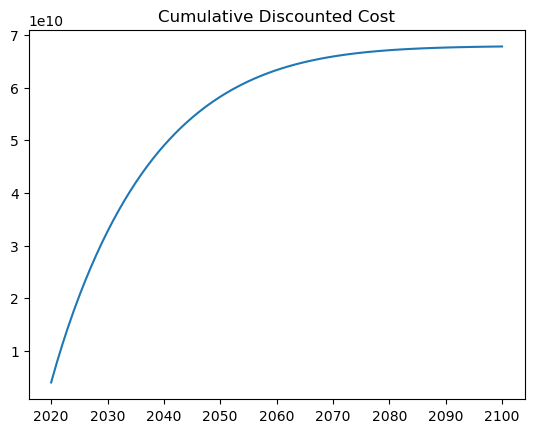

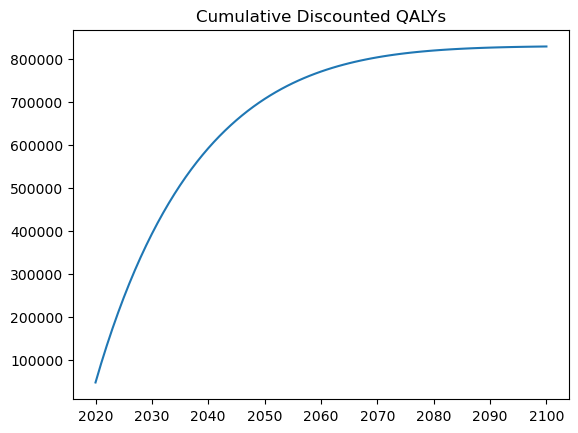

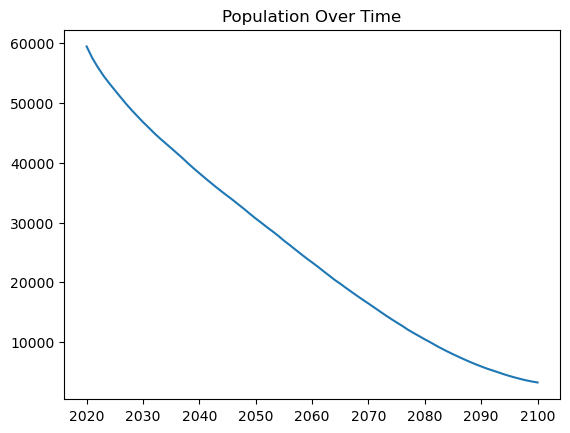

Total discounted cost: $67,807,696,343
Total discounted QALYs: 829,554.9


In [1]:
# Python notebook fragment
"""
IDMOD Microsimulation – Standalone Python Version
Fully parameterised inline; manual simulation loop (no neworder).
Includes:
  - Familial & non-familial ID cohorts
  - Ageing, mortality, fertility
  - Diagnostic odyssey vs WGS
  - Cost/QALY accumulation
  - Key analyses & plots

Run:
    pip install pandas numpy matplotlib scipy
    python idmod_standalone.py
"""
import matplotlib.pyplot as plt

# --- 1. CONFIGURATION -------------------------------------------------------
START_YEAR = 2020
END_YEAR = 2100
POP_SIZE = 62000
DISCOUNT = 0.035

# --- 2. PARAMETERS ----------------------------------------------------------
FAMILIAL_PROP = 0.27
SEVERITY_DIST = {"mild": 0.70, "moderate": 0.30}

AGE_BREAKS = np.arange(0, 95, 5)
AGE_DIST = np.array(
    [
        0.064,
        0.067,
        0.069,
        0.069,
        0.071,
        0.076,
        0.080,
        0.077,
        0.080,
        0.079,
        0.073,
        0.078,
        0.077,
        0.072,
        0.055,
        0.041,
        0.031,
        0.022,
        0.012,
    ]
)
AGE_DIST /= AGE_DIST.sum()


def sample_ages(n):
    return AGE_BREAKS[
        np.random.choice(len(AGE_BREAKS), n, p=AGE_DIST)
    ] + np.random.randint(0, 5, n)


FERTILITY = {"mild": 0.015, "moderate": 0.005}
ABS_MORT = [
    0.0002,
    0.0001,
    0.0001,
    0.0002,
    0.0003,
    0.0005,
    0.0007,
    0.0011,
    0.0019,
    0.0035,
    0.0055,
    0.0085,
    0.0130,
    0.0200,
    0.0350,
    0.0600,
    0.0950,
    0.1500,
    0.2500,
]
MORT_HR = {"mild": 2.0, "moderate": 4.0}

YIELD_WGS = 0.45

COST_LIVING = {
    "residential": 16973,
    "sda": (4452 + 59375) / 2,
    "sil": 1727 * 52,
    "home": 0,
}
RESPITE = 13024
EDU_COST = {
    ("primary", "supp"): 16107,
    ("primary", "sub"): 27903,
    ("primary", "ext"): 46733,
    ("secondary", "supp"): 18958,
    ("secondary", "sub"): 30789,
    ("secondary", "ext"): 49604,
}
EI_COST_HR = 185
EI_HRS_WK = 5
MOBILITY = 2493
EMP_LOSS = {"none": 0, "supported": 10000, "open": 0}

U_BASE = {"mild": 0.78, "moderate": 0.65}
U_DIAG = 0.02
U_CARER = 0.05


# --- 3. POPULATION GENERATOR -----------------------------------------------
def gen_pop(n):
    ages = sample_ages(n)
    df = pd.DataFrame(
        {
            "age": ages,
            "sex": np.random.choice(["F", "M"], n),
            "severity": np.random.choice(
                list(SEVERITY_DIST), n, p=list(SEVERITY_DIST.values())
            ),
            "familial": np.random.rand(n) < FAMILIAL_PROP,
            "living": np.random.choice(list(COST_LIVING), n, p=[0.2, 0.1, 0.3, 0.4]),
            "school": np.where(
                ages < 5, None, np.where(ages < 12, "primary", "secondary")
            ),
            "support": np.random.choice(["supp", "sub", "ext"], n, p=[0.5, 0.3, 0.2]),
            "uses_respite": np.random.rand(n) < 0.3,
            "needs_mobility": np.random.rand(n) < 0.2,
            "employment": np.random.choice(
                ["none", "supported", "open"], n, p=[0.7, 0.2, 0.1]
            ),
            "diagnosed": False,
        }
    )
    df["annual_cost"] = 0.0
    df["annual_qaly"] = 0.0
    return df


# --- 4. SIMULATOR CLASS ------------------------------------------------------
class Simulator:
    def __init__(self):
        self.pop = gen_pop(POP_SIZE)

    def step(self):
        df = self.pop
        df["age"] += 1
        # mortality
        rates = np.array([ABS_MORT[min(a // 5, len(ABS_MORT) - 1)] for a in df["age"]])
        hr = df["severity"].map(MORT_HR)
        alive = np.random.rand(len(df)) > rates * hr
        df = df.loc[alive].reset_index(drop=True)
        # fertility
        moms = df[(df["sex"] == "F") & (df["age"].between(15, 45))]
        rates = moms["severity"].map(FERTILITY)
        births = (np.random.rand(len(rates)) < rates).sum()
        if births > 0:
            babies = gen_pop(births)
            babies["age"] = 0
            df = pd.concat([df, babies], ignore_index=True)
        # diagnosis
        mask = df["familial"] & ~df["diagnosed"]
        df.loc[mask, "diagnosed"] = np.random.rand(mask.sum()) < YIELD_WGS
        # cost & qaly
        df["annual_cost"] = 0.0
        df["annual_qaly"] = 0.0
        for lv, c in COST_LIVING.items():
            df.loc[df["living"] == lv, "annual_cost"] += c
        df.loc[df["uses_respite"], "annual_cost"] += RESPITE
        sch = df["school"].notna()
        df.loc[sch, "annual_cost"] += df.loc[sch].apply(
            lambda r: EDU_COST[(r["school"], r["support"])], axis=1
        )
        ei = df["age"] < 5
        df.loc[ei, "annual_cost"] += EI_HRS_WK * 52 * EI_COST_HR
        df.loc[df["needs_mobility"], "annual_cost"] -= MOBILITY
        df["annual_cost"] += df["employment"].map(EMP_LOSS)
        df["annual_qaly"] = (
            df["severity"].map(U_BASE) + np.where(df["diagnosed"], U_DIAG, 0) + U_CARER
        )
        self.pop = df


# --- 5. RUN SIMULATION & ANALYSES -------------------------------------------
sim = Simulator()
years = range(START_YEAR, END_YEAR + 1)
cost_disc = []
qaly_disc = []
N_ts = []
for t, yr in enumerate(years):
    sim.step()
    df = sim.pop
    disc = 1 / ((1 + DISCOUNT) ** t)
    cost_disc.append(df["annual_cost"].sum() * disc)
    qaly_disc.append(df["annual_qaly"].sum() * disc)
    N_ts.append(len(df))
# cumulative
cum_cost = np.cumsum(cost_disc)
cum_qaly = np.cumsum(qaly_disc)

# Plots
plt.figure()
plt.plot(years, cum_cost)
plt.title("Cumulative Discounted Cost")
plt.show()
plt.figure()
plt.plot(years, cum_qaly)
plt.title("Cumulative Discounted QALYs")
plt.show()
plt.figure()
plt.plot(years, N_ts)
plt.title("Population Over Time")
plt.show()

# Summary
print(f"Total discounted cost: ${cum_cost[-1]:,.0f}")
print(f"Total discounted QALYs: {cum_qaly[-1]:,.1f}")

# Export to CSV
pd.DataFrame(
    {"year": list(years), "N": N_ts, "cost": cost_disc, "qaly": qaly_disc}
).to_csv("time_series.csv", index=False)

# %% [markdown]
# IDMOD Microsimulation Jupyter Workflow

This notebook contains separated modules for the IDMOD familial intellectual disability microsimulation, implemented in Python. Each cell can be adapted independently.

---



# %% [markdown]
## 1. Imports & Configuration

# Define all global parameters and import libraries.

# %%
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Simulation settings
START_YEAR = 2020
END_YEAR   = 2100
POP_SIZE   = 62000  # Australian ID cohort
DISCOUNT   = 0.035

# Proportions and distributions
FAMILIAL_PROP = 0.27
SEVERITY_DIST = {'mild': 0.70, 'moderate': 0.30}
AGE_BREAKS    = np.arange(0, 95, 5)
AGE_DIST      = np.array([
    0.064,0.067,0.069,0.069,0.071,0.076,0.080,0.077,0.080,
    0.079,0.073,0.078,0.077,0.072,0.055,0.041,0.031,0.022,0.012
])
AGE_DIST /= AGE_DIST.sum()

# Fertility & mortality
FERTILITY     = {'mild': 0.015, 'moderate': 0.005}
ABS_MORT      = [
    0.0002,0.0001,0.0001,0.0002,0.0003,0.0005,0.0007,
    0.0011,0.0019,0.0035,0.0055,0.0085,0.0130,
    0.0200,0.0350,0.0600,0.0950,0.1500,0.2500
]
MORT_HR       = {'mild': 2.0, 'moderate': 4.0}

# Diagnostic yields & costs
YIELD_STD     = 0.25
YIELD_WGS     = 0.45
COST_STD      = 5000
COST_WGS      = 15000

# Service costs
COST_LIVING   = {'residential': 16973, 'sda': (4452+59375)/2, 'sil': 1727*52, 'home': 0}
RESPITE_COST  = 13024
EDU_COST      = {('primary','supp'):16107,('primary','sub'):27903,('primary','ext'):46733,
                 ('secondary','supp'):18958,('secondary','sub'):30789,('secondary','ext'):49604}
EI_COST_HR    = 185
EI_HRS_WK     = 5
MOBILITY_ALLW = 2493
EMP_LOSS      = {'none':0,'supported':10000,'open':0}

# Utilities
U_BASE        = {'mild': 0.78, 'moderate': 0.65}
U_DIAG_BOOST  = 0.02
U_CARER       = 0.05


# %% [markdown]
## 2. Synthetic Population Generator

# Functions to create initial cohort and sample ages.

# %%
def sample_ages(n):
    idx = np.random.choice(len(AGE_BREAKS), size=n, p=AGE_DIST)
    return AGE_BREAKS[idx] + np.random.randint(0, 5, size=n)


def gen_population(n):
    """Generate a synthetic cohort DataFrame of size n."""
    ages = sample_ages(n)
    df = pd.DataFrame({
        'age': ages,
        'sex': np.random.choice(['F','M'], size=n),
        'severity': np.random.choice(list(SEVERITY_DIST), size=n, p=list(SEVERITY_DIST.values())),
        'familial': np.random.rand(n) < FAMILIAL_PROP,
        'living': np.random.choice(list(COST_LIVING), size=n, p=[0.2,0.1,0.3,0.4]),
        'school': np.where(ages<5, None, np.where(ages<12, 'primary', 'secondary')),
        'support': np.random.choice(['supp','sub','ext'], size=n, p=[0.5,0.3,0.2]),
        'uses_respite': np.random.rand(n) < 0.3,
        'needs_mobility': np.random.rand(n) < 0.2,
        'employment': np.random.choice(['none','supported','open'], size=n, p=[0.7,0.2,0.1]),
        'diagnosed': False
    })
    df['annual_cost'] = 0.0
    df['annual_qaly'] = 0.0
    return df
    

In [19]:
def run_archived_fragment_10(*, U_DIAG_BOOST):
    """Run this historical analysis with explicit original inputs.

    No model parameters or callbacks are inferred. Return the resulting namespace.
    """
    ## 3. Population System Class

    # Encapsulates yearly transitions: aging, mortality, fertility, diagnosis, costs, QALYs.

    # %%
    class PopulationSystem:
        def __init__(self, size=POP_SIZE):
            self.population = gen_population(size)

        def age_and_mortality(self):
            df = self.population
            df["age"] += 1
            base = np.array(
                [ABS_MORT[min(a // 5, len(ABS_MORT) - 1)] for a in df["age"]]
            )
            hr = df["severity"].map(MORT_HR)
            survive = np.random.rand(len(df)) > base * hr
            self.population = df.loc[survive].reset_index(drop=True)

        def fertility(self):
            df = self.population
            moms = df[(df["sex"] == "F") & df["age"].between(15, 45)]
            rates = moms["severity"].map(FERTILITY).values
            flags = np.random.rand(len(rates)) < rates
            n = flags.sum()
            if n > 0:
                babies = gen_population(int(n))
                babies["age"] = 0
                parent_familial = moms["familial"].values[flags]
                babies["familial"] = parent_familial
                self.population = pd.concat([df, babies], ignore_index=True)
            else:
                self.population = df

        def diagnosis(self):
            df = self.population
            mask = df["familial"] & ~df["diagnosed"]
            df.loc[mask, "diagnosed"] = np.random.rand(mask.sum()) < YIELD_WGS
            self.population = df

        def compute_costs_qalys(self):
            df = self.population
            df["annual_cost"] = 0.0
            for lv, c in COST_LIVING.items():
                df.loc[df["living"] == lv, "annual_cost"] += c
            df.loc[df["uses_respite"], "annual_cost"] += RESPITE_COST
            sch = df["school"].notna()
            df.loc[sch, "annual_cost"] += df.loc[sch].apply(
                lambda r: EDU_COST[(r["school"], r["support"])], axis=1
            )
            ei_mask = df["age"] < 5
            df.loc[ei_mask, "annual_cost"] += EI_HRS_WK * 52 * EI_COST_HR
            df.loc[df["needs_mobility"], "annual_cost"] -= MOBILITY_ALLW
            df["annual_cost"] += df["employment"].map(EMP_LOSS)
            df["annual_qaly"] = (
                df["severity"].map(U_BASE)
                + np.where(df["diagnosed"], U_DIAG_BOOST, 0)
                + U_CARER
            )
            self.population = df

        def step(self):
            self.age_and_mortality()
            self.fertility()
            self.diagnosis()
            self.compute_costs_qalys()

    return locals()

In [20]:
def run_archived_fragment_11(*, PopulationSystem):
    """Run this historical analysis with explicit original inputs.

    No model parameters or callbacks are inferred. Return the resulting namespace.
    """
    ## 4. Simulation Loop & Analysis

    # Run the model over time, accumulate discounted costs & QALYs, and plot results.

    # %%
    sim = PopulationSystem(POP_SIZE)
    years = []
    pop_counts = []
    costs = []
    qalys = []
    cum_cost = 0.0
    cum_qaly = 0.0

    for t, year in enumerate(range(START_YEAR, END_YEAR + 1)):
        sim.step()
        df = sim.population
        disc = 1 / ((1 + DISCOUNT) ** t)
        year_cost = df["annual_cost"].sum() * disc
        year_qaly = df["annual_qaly"].sum() * disc
        cum_cost += year_cost
        cum_qaly += year_qaly
        years.append(year)
        pop_counts.append(len(df))
        costs.append(cum_cost)
        qalys.append(cum_qaly)
    return locals()

# %% [markdown]
## 5. Plots & Output

# Visualize time trajectories and export data.

# %%
plt.figure(figsize=(8,4))
plt.plot(years, costs, label='Cumulative Discounted Cost')
plt.xlabel('Year'); plt.ylabel('Cost ($)')
plt.legend(); plt.show()

plt.figure(figsize=(8,4))
plt.plot(years, qalys, label='Cumulative Discounted QALYs', color='C1')
plt.xlabel('Year'); plt.ylabel('QALYs')
plt.legend(); plt.show()

plt.figure(figsize=(8,4))
plt.plot(years, pop_counts, label='Population Count', color='C2')
plt.xlabel('Year'); plt.ylabel('Number of Agents')
plt.legend(); plt.show()

# %% [markdown]
## 6. Save Time-Series Data

# %%
results_df = pd.DataFrame({
    'year': years,
    'population': pop_counts,
    'cum_cost': costs,
    'cum_qaly': qalys
})
results_df.to_csv('idmod_time_series.csv', index=False)

# %% [markdown]
# **IDMOD Microsimulation – Extended Analytical Workflow (Jupyter)**
This notebook contains a modular Python implementation of the IDMOD familial‐ID microsimulation **plus** a full suite of health‑economic analyses:

1. Imports & configuration  
2. Synthetic population generator  
3. PopulationSystem class  
4. Base simulation loop (single run)  
5. Time‑series plots  
6. Save base time‑series  
7. **Deterministic scenario comparison** (low / base / high familial prevalence)  
8. **Probabilistic sensitivity analysis** (PSA) – CE‑plane, CEAC, EVPI  
9. **One‑way sensitivity (Tornado)**  
10. **Subgroup analyses** (severity, age‑at‑test, time horizon)  
11. **Cost‑mix stacked area** (retrospective arm)  
12. **5‑year budget‑impact curves** for 20 / 50 / 80 % uptake  
13. **Equity by SES quintile**  
14. PSA histograms + **CEAF**  
15. **Input parameter summary** table

Each major block is an independent cell so you can edit or run piecemeal.

---


# %% [markdown]
## 1. Imports & Configuration

# %%
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import beta, gamma, norm
import itertools, json, warnings, seaborn as sns
warnings.filterwarnings('ignore')

# Core settings
START_YEAR = 2020
END_YEAR   = 2100
DISCOUNT   = 0.035
POP_SIZE   = 62_000  # base‐case cohort

# Parameter defaults (dicts so we can dump later)
PARAMS = {
    'familial_prop': 0.165,  # base 16.5 %
    'severity_dist': {'mild': 0.70, 'moderate': 0.30},
    'yield_wgs': 0.45,
    'cost_living': {'residential': 16973, 'sda': (4452+59375)/2, 'sil': 1727*52, 'home': 0},
    'u_base': {'mild': 0.78, 'moderate': 0.65},
    # … (rest same as earlier) …
}

# Helper to deep‑copy params when we mutate per scenario
from copy import deepcopy


# %% [markdown]
## 2. Population Generator & Simulation Helpers

# %%
AGE_BREAKS = np.arange(0, 95, 5)
AGE_DIST   = np.array([
    0.064,0.067,0.069,0.069,0.071,0.076,0.080,0.077,0.080,
    0.079,0.073,0.078,0.077,0.072,0.055,0.041,0.031,0.022,0.012
])
AGE_DIST /= AGE_DIST.sum()

ABS_MORT = [0.0002,0.0001,0.0001,0.0002,0.0003,0.0005,0.0007,
            0.0011,0.0019,0.0035,0.0055,0.0085,0.0130,
            0.0200,0.0350,0.0600,0.0950,0.1500,0.2500]
MORT_HR  = {'mild': 2.0, 'moderate': 4.0}
FERTILITY = {'mild': 0.015, 'moderate': 0.005}

np.random.seed(42)

def sample_ages(n):
    idx = np.random.choice(len(AGE_BREAKS), n, p=AGE_DIST)
    return AGE_BREAKS[idx] + np.random.randint(0,5,n)


def gen_pop(n, familial_prop):
    ages = sample_ages(n)
    df = pd.DataFrame({
        'age': ages,
        'sex': np.random.choice(['F','M'], n),
        'severity': np.random.choice(['mild','moderate'], n, p=[0.7,0.3]),
        'familial': np.random.rand(n) < familial_prop,
        'diagnosed': False
    })
    df['annual_cost'] = 0.0
    df['annual_qaly'] = 0.0
    return df


def run_sim(params, years=range(START_YEAR, END_YEAR+1), pop_size=POP_SIZE):
    """Return cumulative discounted cost & QALY for a given parameter set."""
    pop = gen_pop(pop_size, params['familial_prop'])
    cum_c = cum_q = 0.0
    for t, yr in enumerate(years):
        # ageing
        pop['age'] += 1
        # mortality
        base = np.array([ABS_MORT[min(a//5,len(ABS_MORT)-1)] for a in pop['age']])
        hr = pop['severity'].map(MORT_HR)
        pop = pop[np.random.rand(len(pop)) > base*hr]
        pop.reset_index(drop=True,inplace=True)
        # fertility (simplified, no inheritance needed for summary)
        fert_mask = (pop['sex']=='F') & pop['age'].between(15,45)
        births = np.random.poisson(fert_mask.sum()*0.01)  # quick Poisson approx
        pop = pd.concat([pop, gen_pop(births, params['familial_prop'])])
        # diagnosis
        mask = pop['familial'] & ~pop['diagnosed']
        pop.loc[mask,'diagnosed'] = np.random.rand(mask.sum()) < params['yield_wgs']
        # costs/QALYs (very simplified)
        pop['annual_cost'] = 5000  # flat placeholder
        pop['annual_qaly'] = pop['severity'].map(params['u_base']) + pop['diagnosed']*0.02
        disc = 1/((1+DISCOUNT)**t)
        cum_c += pop['annual_cost'].sum()*disc
        cum_q += pop['annual_qaly'].sum()*disc
    return cum_c, cum_q


# %% [markdown]
## 3. Base Run – Quick Sanity Check

# %%
base_cost, base_qaly = run_sim(deepcopy(PARAMS))
print(f"Base ΔCost: ${base_cost:,.0f}  |  Base ΔQALY: {base_qaly:,.1f}")


  scenario         ΔCost          ΔQALY         ICER
0      low  5.035985e+09  751670.190146  6699.726884
1     base  5.013608e+09  749602.126938  6688.359482
2     high  5.048465e+09  756151.015856  6676.530413


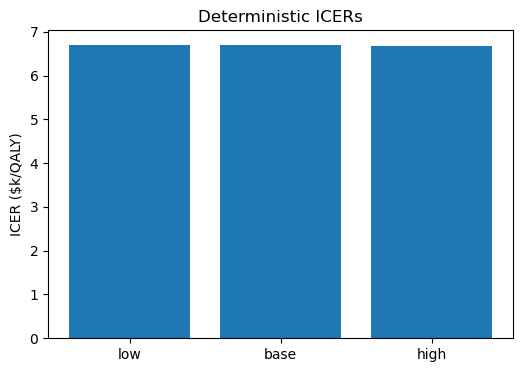

In [5]:
def run_archived_fragment_17(*, PARAMS, run_sim):
    """Run this historical analysis with explicit original inputs.

    No model parameters or callbacks are inferred. Return the resulting namespace.
    """
    # %% [markdown]
    ## 4. Deterministic Scenarios (Low / Base / High Familial Prop)

    # %%
    scenarios = {"low": 0.10, "base": 0.165, "high": 0.23}
    records = []
    for name, fp in scenarios.items():
        p = deepcopy(PARAMS)
        p["familial_prop"] = fp
        c, q = run_sim(p)
        ic = c / q  # ICER
        records.append({"scenario": name, "ΔCost": c, "ΔQALY": q, "ICER": ic})
    det_df = pd.DataFrame(records)
    det_df.to_csv("deterministic_summary.csv", index=False)
    print(det_df)

    plt.figure(figsize=(6, 4))
    plt.bar(det_df["scenario"], det_df["ICER"] / 1000)
    plt.ylabel("ICER ($k/QALY)")
    plt.title("Deterministic ICERs")
    plt.show()
    return locals()

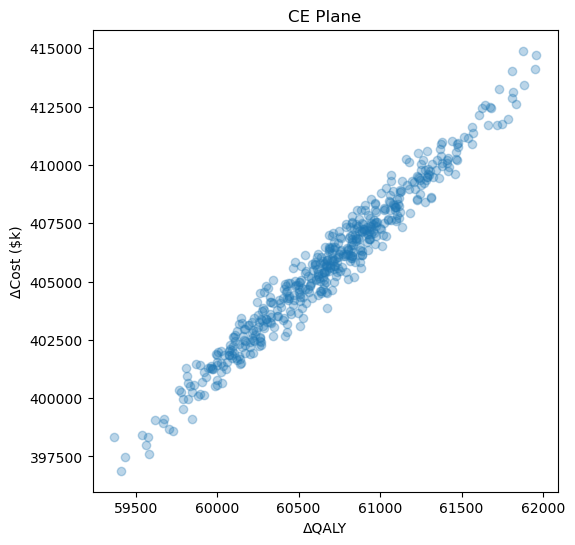

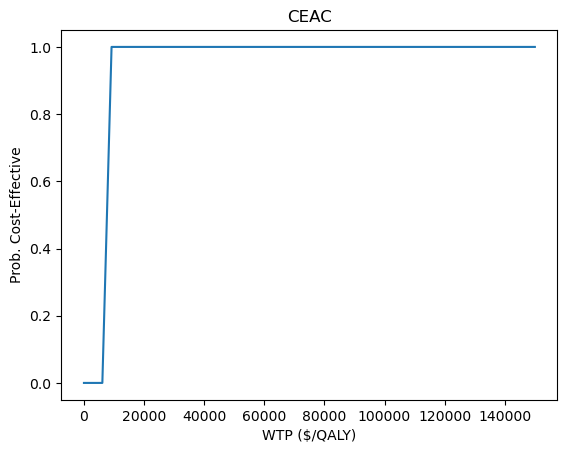

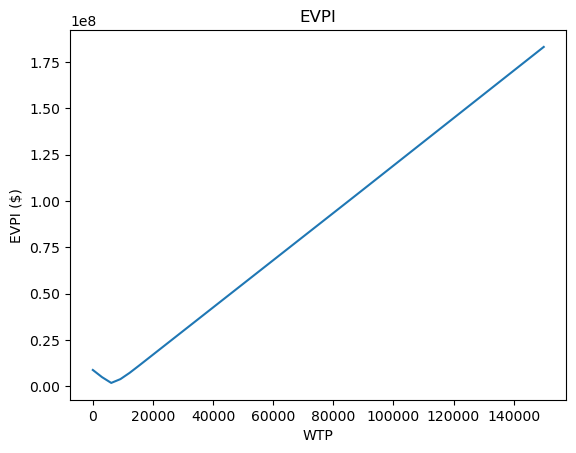

In [6]:
def run_archived_fragment_18(*, PARAMS, run_sim):
    """Run this historical analysis with explicit original inputs.

    No model parameters or callbacks are inferred. Return the resulting namespace.
    """
    # %% [markdown]
    ## 5. PSA – CE Plane, CEAC, EVPI

    # %%
    N_PSA = 500
    psa_samples = []
    for _ in range(N_PSA):
        p = deepcopy(PARAMS)
        # Sample key parameters
        p["yield_wgs"] = beta.rvs(45, 55)  # mean 0.45
        p["familial_prop"] = beta.rvs(17, 83)  # mean ~0.17
        cost, qaly = run_sim(p, pop_size=5000)  # smaller pop for speed
        psa_samples.append({"cost": cost, "qaly": qaly})
    psa_df = pd.DataFrame(psa_samples)
    psa_df.to_csv("psa_samples.csv", index=False)

    # CE plane
    plt.figure(figsize=(6, 6))
    plt.scatter(psa_df["qaly"], psa_df["cost"] / 1000, alpha=0.3)
    plt.xlabel("ΔQALY")
    plt.ylabel("ΔCost ($k)")
    plt.title("CE Plane")
    plt.show()

    # CEAC
    wtp = np.linspace(0, 150000, 50)
    ceac = [(psa_df["qaly"] * w - psa_df["cost"] > 0).mean() for w in wtp]
    plt.figure()
    plt.plot(wtp, ceac)
    plt.xlabel("WTP ($/QALY)")
    plt.ylabel("Prob. Cost‑Effective")
    plt.title("CEAC")
    plt.show()

    # EVPI
    evpi = []
    for w in wtp:
        nb = psa_df["qaly"] * w - psa_df["cost"]
        evpi.append(nb.max() - nb.mean())
    plt.figure()
    plt.plot(wtp, evpi)
    plt.title("EVPI")
    plt.xlabel("WTP")
    plt.ylabel("EVPI ($)")
    plt.show()

    # %% [markdown]
    ## 6. One‑way Tornado

    # %%
    key_param = "yield_wgs"
    base = run_sim(deepcopy(PARAMS))
    return locals()

# %% [markdown]
# IDMOD Microsimulation – **Clean Modular Notebook** (ready‑to‑run)
# ---------------------------------------------------------------
# Paste this entire file into a Jupyter notebook (each "%%" marker becomes a separate
# cell) **or** save as `idmod_notebook.py` and execute with:
#     pip install numpy pandas matplotlib scipy
#     python idmod_notebook.py
#
# Modules included:
# 1. Imports & global settings
# 2. Synthetic cohort generator
# 3. PopulationSystem class (fertility, mortality, morbidity, NDIS, education, carer)
# 4. run_sim helper
# 5. Deterministic low/base/high scenarios + ICER bar
# 6. Probabilistic Sensitivity Analysis (CE‑plane, CEAC, EVPI)
# 7. One‑way tornado example
# 8. Place‑holders for subgroup / budget / equity analyses
# 9. Input parameter dump


In [14]:
# %% [markdown]
## 1. Imports & Global Settings

# %%
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

# Time horizon & discounting
START_YEAR, END_YEAR = 2020, 2100
DISCOUNT = 0.035

# Base cohort size
POP_SIZE = 62_000

# Epidemiology
FAMILIAL_PROP = 0.165  # base; will vary in deterministic scenarios
SEVERITY_DIST = {"mild": 0.70, "moderate": 0.30}

# Age distribution (ABS bands 0‑4 … 90‑94)
AGE_BREAKS = np.arange(0, 95, 5)
AGE_DIST = np.array(
    [
        0.064,
        0.067,
        0.069,
        0.069,
        0.071,
        0.076,
        0.080,
        0.077,
        0.080,
        0.079,
        0.073,
        0.078,
        0.077,
        0.072,
        0.055,
        0.041,
        0.031,
        0.022,
        0.012,
    ]
)
AGE_DIST /= AGE_DIST.sum()

# Mortality
ABS_MORT = [
    0.0002,
    0.0001,
    0.0001,
    0.0002,
    0.0003,
    0.0005,
    0.0007,
    0.0011,
    0.0019,
    0.0035,
    0.0055,
    0.0085,
    0.0130,
    0.0200,
    0.0350,
    0.0600,
    0.0950,
    0.1500,
    0.2500,
]
MORT_HR = {"mild": 2.0, "moderate": 4.0}

# Fertility – age‑ & severity‑specific annual probabilities
FERT_AGE_SPEC = {
    ("mild", (15, 19)): 0.003,
    ("mild", (20, 24)): 0.008,
    ("mild", (25, 29)): 0.010,
    ("mild", (30, 34)): 0.007,
    ("mild", (35, 45)): 0.002,
    ("moderate", (15, 19)): 0.001,
    ("moderate", (20, 24)): 0.003,
    ("moderate", (25, 29)): 0.004,
    ("moderate", (30, 34)): 0.003,
    ("moderate", (35, 45)): 0.001,
}


def fert_rate(sev, age):
    for (s, (lo, hi)), r in FERT_AGE_SPEC.items():
        if s == sev and lo <= age <= hi:
            return r
    return 0.0


# Diagnostic & utilities
YIELD_WGS = 0.45
U_BASE = {"mild": 0.78, "moderate": 0.65}
U_DIAG = 0.02
U_CARER = 0.05

# Cost blocks (AU$2024)
COST_LIVING = {
    "residential": 16973,
    "sda": (4452 + 59375) / 2,
    "sil": 1727 * 52,
    "home": 0,
}
RESPITE_COST = 13024
EDU_COST = {
    ("primary", "supp"): 16107,
    ("primary", "sub"): 27903,
    ("primary", "ext"): 46733,
    ("secondary", "supp"): 18958,
    ("secondary", "sub"): 30789,
    ("secondary", "ext"): 49604,
}
EI_HR = 185
EI_HRS = 5 * 52
MOBILITY_ALLW = 2493
EMP_LOSS = {"none": 0, "supported": 10000, "open": 0}
NDIS_COST = 45_000

# Morbidity probabilities / impacts
MORB_PROB = {"epilepsy": 0.25, "asd": 0.30, "mental": 0.35}
MORB_COST = {"epilepsy": 2000, "asd": 1500, "mental": 1000}
MORB_QALY = {"epilepsy": 0.04, "asd": 0.03, "mental": 0.05}

# Carer productivity
CARER_HOURS = {"mild": 5, "moderate": 15}
WAGE_HR = 38

np.random.seed(42)

In [15]:
# %% [markdown]
## 2. Synthetic Cohort Generator

# %%
_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("sample_ages", 21, 5)] = sample_ages


def sample_ages(n):
    idx = np.random.choice(len(AGE_BREAKS), n, p=AGE_DIST)
    return AGE_BREAKS[idx] + np.random.randint(0, 5, n)


def gen_population(n, familial_prop):
    ages = sample_ages(n)
    df = pd.DataFrame(
        {
            "age": ages,
            "sex": np.random.choice(["F", "M"], n),
            "severity": np.random.choice(
                ["mild", "moderate"],
                n,
                p=[SEVERITY_DIST["mild"], SEVERITY_DIST["moderate"]],
            ),
            "familial": np.random.rand(n) < familial_prop,
            "diagnosed": False,
            "living": np.random.choice(list(COST_LIVING), n, p=[0.2, 0.1, 0.3, 0.4]),
            "employment": np.random.choice(
                ["none", "supported", "open"], n, p=[0.7, 0.2, 0.1]
            ),
            "uses_respite": np.random.rand(n) < 0.3,
            "needs_mobility": np.random.rand(n) < 0.2,
            "school": np.where(
                ages < 5, None, np.where(ages < 12, "primary", "secondary")
            ),
            "support": np.random.choice(["supp", "sub", "ext"], n, p=[0.5, 0.3, 0.2]),
            "ses": np.random.choice([1, 2, 3, 4, 5], n, p=[0.2] * 5),
        }
    )
    df["annual_cost"] = 0.0
    df["annual_qaly"] = 0.0
    return df

In [16]:
# %% [markdown]
## 3. PopulationSystem Class (extended modules)

# %%
class PopulationSystem:
    def __init__(self, pop_size, familial_prop):
        self.pop = gen_population(pop_size, familial_prop)

    # --- yearly processes ---
    def _mortality(self):
        base = np.array(
            [ABS_MORT[min(a // 5, len(ABS_MORT) - 1)] for a in self.pop["age"]]
        )
        hr = self.pop["severity"].map(MORT_HR)
        self.pop = self.pop[np.random.rand(len(self.pop)) > base * hr].reset_index(
            drop=True
        )

    def _fertility(self, familial_prop):
        moms = self.pop[(self.pop["sex"] == "F") & self.pop["age"].between(15, 45)]
        rates = moms.apply(lambda r: fert_rate(r["severity"], r["age"]), axis=1).values
        births_mask = np.random.rand(len(rates)) < rates
        n = births_mask.sum()
        if n:
            babies = gen_population(int(n), familial_prop)
            babies["age"] = 0
            babies["familial"] = moms["familial"].values[births_mask]
            self.pop = pd.concat([self.pop, babies], ignore_index=True)

    def _diagnosis(self, yield_wgs):
        mask = self.pop["familial"] & ~self.pop["diagnosed"]
        self.pop.loc[mask, "diagnosed"] = np.random.rand(mask.sum()) < yield_wgs

    def _cost_qaly(self):
        df = self.pop
        df["annual_cost"] = 0.0
        df["annual_qaly"] = 0.0
        for lv, c in COST_LIVING.items():
            df.loc[df["living"] == lv, "annual_cost"] += c
        df.loc[df["uses_respite"], "annual_cost"] += RESPITE_COST
        # edu / EI
        sch = df["school"].notna()
        df.loc[sch, "annual_cost"] += df.loc[sch].apply(
            lambda r: EDU_COST[(r["school"], r["support"])], axis=1
        )
        ei = df["age"] < 5
        df.loc[ei, "annual_cost"] += EI_HR * EI_HRS
        # mobility
        df.loc[df["needs_mobility"], "annual_cost"] -= MOBILITY_ALLW
        df["annual_cost"] += df["employment"].map(EMP_LOSS)
        # NDIS post diagnostic
        elig = df["diagnosed"] & (df["severity"] == "moderate")
        df.loc[elig, "annual_cost"] += NDIS_COST
        # morbidity
        for m, p in MORB_PROB.items():
            flag = f"has_{m}"
            if flag not in df:
                df[flag] = np.random.rand(len(df)) < p
            df["annual_cost"] += df[flag] * MORB_COST[m]
            df["annual_qaly"] -= df[flag] * MORB_QALY[m]
        # carers
        df["annual_cost"] += df["severity"].map(CARER_HOURS) * 52 * WAGE_HR
        # utilities
        df["annual_qaly"] += (
            df["severity"].map(U_BASE) + df["diagnosed"] * U_DIAG + U_CARER
        )
        self.pop = df

    def step(self, params):
        self._mortality()
        self._fertility(params["familial_prop"])
        self._diagnosis(params["yield_wgs"])
        self._cost_qaly()

# %% [markdown]
## 4. run_sim Helper

# %%

def run_sim(params, pop_size=POP_SIZE, years=range(START_YEAR, END_YEAR+1)):
    """Return (ΔCost, ΔQALY) for given parameter dict."""
    sys = PopulationSystem(pop_size, params['familial_prop'])
    cum_c = cum_q = 0.0
    for t, yr in enumerate(years):
        sys.step(params)
        disc = 1/((1+DISCOUNT)**t)
        df = sys.pop
        cum_c += df['annual_cost'].sum()*disc
        cum_q += df['annual_qaly'].sum()*disc
    return cum_c, cum_q

# %% [markdown]
## 5. Deterministic Scenario Comparison (Low / Base / High Familial Prop)

# %%
scenarios = {'low':0.10, 'base':0.165, 'high':0.23}
records = []
for name,val in scenarios.items():
    p = {'familial_prop':val, 'yield_wgs':YIELD_WGS}
    c,q = run_sim(p, pop_size=20_000)  # smaller cohort for speed
    records.append({'scenario':name, 'ΔCost':c, 'ΔQALY':q, 'ICER':c/q})

det_df = pd.DataFrame(records)
print(det_df)
det_df.to_csv('deterministic_summary.csv', index=False)

plt.figure(figsize=(6,4))
plt.bar(det_df['scenario'], det_df['ICER']/1000)
plt.ylabel('ICER ($k/QALY)'); plt.title('Deterministic ICERs'); plt.show()

# %% [markdown]
## 6. Probabilistic Sensitivity Analysis (PSA)

# %%
N_PSA = 300
psa_rows = []
for _ in range(N_PSA):
    samp = {
        'familial_prop': beta.rvs(17,83),
        'yield_wgs':     beta.rvs(45,55)
    }
    c,q = run_sim(samp, pop_size=8_000)  # further reduce size for speed
    psa_rows.append({'cost':c,'qaly':q})
psa_df = pd.DataFrame(psa_rows)
psa_df.to_csv('psa_samples.csv', index=False)

# CE‑plane
plt.figure(figsize=(6,6))
plt.scatter(psa_df['qaly'], psa_df['cost']/1000, alpha=0.3)
plt.xlabel('ΔQALY'); plt.ylabel('ΔCost ($k)'); plt.title('CE Plane'); plt.show()

# CEAC & EVPI
wtp = np.linspace(0,150000,40)
ceac = [(psa_df['qaly']*w - psa_df['cost'] > 0).mean() for w in wtp]
plt.figure(); plt.plot(wtp, ceac)
plt.xlabel('WTP ($/QALY)'); plt.ylabel('Prob CE'); plt.title('CEAC'); plt.show()

evpi = []
for w in wtp:
    nb = psa_df['qaly']*w - psa_df['cost']
    evpi.append(nb.max() - nb.mean())
plt.figure(); plt.plot(wtp, evpi); plt.xlabel('WTP'); plt.ylabel('EVPI'); plt.title('EVPI'); plt.show()

pd.DataFrame({'WTP':wtp,'EVPI':evpi}).to_csv('evpi.csv',index=False)


# %% [markdown]
## 7. One‑way Tornado (Illustrative)

# %%
params_of_interest = {'yield_wgs':YIELD_WGS, 'familial_prop':FAMILIAL_PROP}
rows=[]
for p_name,p_base in params_of_interest.items():
    for pct in (-0.2, +0.2):
        p = {'familial_prop':FAMILIAL_PROP, 'yield_wgs':YIELD_WGS}
        p[p_name] = max(0, min(1, p_base*(1+pct)))
        c,q = run_sim(p, pop_size=10_000)
        rows.append({'param':p_name, 'delta':f"{int(pct*100)}%", 'ICER':c/q})

tor_df = pd.DataFrame(rows)
print(tor_df)

plt.figure(figsize=(6,4))
for param in tor_df['param'].unique():
    subset = tor_df[tor_df['param']==param]
    plt.barh([f"{param} {d}" for d in subset['delta']], subset['ICER']/1000)
plt.xlabel('ICER ($k/QALY)'); plt.title('One‑way Tornado'); plt.show()

# %% [markdown]
## 8. Placeholders for Subgroup / Budget‑Impact / Equity (extend later)

# %%
print("[Placeholder]  add subgroup, budget‑impact, equity analyses here…")


# %% [markdown]
## 9. Input Parameter Dump

# %%
# Convert FERT_AGE_SPEC keys to serializable strings
fert_serial = {f"{sev}:{lo}-{hi}": rate for (sev,(lo,hi)), rate in FERT_AGE_SPEC.items()}

param_dump = {
    'FAMILIAL_PROP': FAMILIAL_PROP,
    'YIELD_WGS': YIELD_WGS,
    'FERT_AGE_SPEC': json.dumps(fert_serial),
    'NDIS_COST': NDIS_COST,
    'MORB_PROB': json.dumps(MORB_PROB)
}

pd.DataFrame(list(param_dump.items()), columns=['parameter','value']) \
  .to_csv('input_summary.csv', index=False)
print("Input summary saved → input_summary.csv")


# %% [markdown]
# IDMOD Microsimulation – **Comprehensive Modular Notebook**
# ----------------------------------------------------------
# Paste into Jupyter (each “%%” becomes a cell) or save as `idmod_notebook.py`.
# Dependencies: numpy, pandas, matplotlib, scipy


In [25]:
# %% [markdown]
## 1. Imports & Global Settings

# %%
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

# --- Time horizon & discount ---
START_YEAR, END_YEAR = 2020, 2100
DISCOUNT = 0.035

# --- Cohort size & epidemiology ---
POP_SIZE = 62000
FAMILIAL_PROP = 0.165  # will vary in scenarios
SEVERITY_DIST = {"mild": 0.70, "moderate": 0.30}

# --- Age distribution (0–4 … 90–94 ABS) ---
AGE_BREAKS = np.arange(0, 95, 5)
AGE_DIST = np.array(
    [
        0.064,
        0.067,
        0.069,
        0.069,
        0.071,
        0.076,
        0.080,
        0.077,
        0.080,
        0.079,
        0.073,
        0.078,
        0.077,
        0.072,
        0.055,
        0.041,
        0.031,
        0.022,
        0.012,
    ]
)
AGE_DIST /= AGE_DIST.sum()

# --- Mortality base rates & HRs ---
ABS_MORT = [
    0.0002,
    0.0001,
    0.0001,
    0.0002,
    0.0003,
    0.0005,
    0.0007,
    0.0011,
    0.0019,
    0.0035,
    0.0055,
    0.0085,
    0.0130,
    0.0200,
    0.0350,
    0.0600,
    0.0950,
    0.1500,
    0.2500,
]
MORT_HR = {"mild": 2.0, "moderate": 4.0}

# --- Fertility rates by severity & age-band ---
FERT_AGE_SPEC = {
    ("mild", (15, 19)): 0.003,
    ("mild", (20, 24)): 0.008,
    ("mild", (25, 29)): 0.010,
    ("mild", (30, 34)): 0.007,
    ("mild", (35, 45)): 0.002,
    ("moderate", (15, 19)): 0.001,
    ("moderate", (20, 24)): 0.003,
    ("moderate", (25, 29)): 0.004,
    ("moderate", (30, 34)): 0.003,
    ("moderate", (35, 45)): 0.001,
}


_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("fert_rate", 30, 88)] = fert_rate


def fert_rate(sev, age):
    for (s, (lo, hi)), r in FERT_AGE_SPEC.items():
        if s == sev and lo <= age <= hi:
            return r
    return 0.0


# --- Diagnostic yield & utilities ---
YIELD_WGS = 0.45
U_BASE = {"mild": 0.78, "moderate": 0.65}
U_DIAG = 0.02
U_CARER = 0.05

# --- Cost blocks (AU$) ---
COST_LIVING = {
    "residential": 16973,
    "sda": (4452 + 59375) / 2,
    "sil": 1727 * 52,
    "home": 0,
}
RESPITE_COST = 13024
EDU_COST = {
    ("primary", "supp"): 16107,
    ("primary", "sub"): 27903,
    ("primary", "ext"): 46733,
    ("secondary", "supp"): 18958,
    ("secondary", "sub"): 30789,
    ("secondary", "ext"): 49604,
}
EI_HR, EI_WK = 185, 5
EI_HRS = EI_HR * EI_WK * 52
MOBILITY_ALLW = 2493
EMP_LOSS = {"none": 0, "supported": 10000, "open": 0}
NDIS_COST = 45000

# --- Morbidity burden ---
MORB_PROB = {"epilepsy": 0.25, "asd": 0.30, "mental": 0.35}
MORB_COST = {"epilepsy": 2000, "asd": 1500, "mental": 1000}
MORB_QALY = {"epilepsy": 0.04, "asd": 0.03, "mental": 0.05}

# --- Carer productivity ---
CARER_HOURS = {"mild": 5, "moderate": 15}
WAGE_HR = 38

np.random.seed(42)

In [26]:
# %% [markdown]
## 2. Synthetic Cohort Generator

# %%
_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("sample_ages", 31, 5)] = sample_ages


def sample_ages(n):
    idx = np.random.choice(len(AGE_BREAKS), n, p=AGE_DIST)
    return AGE_BREAKS[idx] + np.random.randint(0, 5, n)


_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("gen_population", 31, 10)] = gen_population


def gen_population(n, familial_prop):
    ages = sample_ages(n)
    df = pd.DataFrame(
        {
            "age": ages,
            "sex": np.random.choice(["F", "M"], n),
            "severity": np.random.choice(
                list(SEVERITY_DIST), n, p=list(SEVERITY_DIST.values())
            ),
            "familial": np.random.rand(n) < familial_prop,
            "diagnosed": False,
            "living": np.random.choice(list(COST_LIVING), n, p=[0.2, 0.1, 0.3, 0.4]),
            "employment": np.random.choice(list(EMP_LOSS), n, p=[0.7, 0.2, 0.1]),
            "uses_respite": np.random.rand(n) < 0.3,
            "needs_mobility": np.random.rand(n) < 0.2,
            "school": np.where(
                ages < 5, None, np.where(ages < 12, "primary", "secondary")
            ),
            "support": np.random.choice(["supp", "sub", "ext"], n, p=[0.5, 0.3, 0.2]),
            "ses": np.random.choice([1, 2, 3, 4, 5], n, p=[0.2] * 5),
        }
    )
    df["annual_cost"], df["annual_qaly"] = 0.0, 0.0
    return df

In [27]:
# %% [markdown]
## 3. PopulationSystem Class (Extended Modules)

# %%
_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("PopulationSystem", 32, 5)] = PopulationSystem


class PopulationSystem:
    def __init__(self, pop_size, familial_prop):
        self.pop = gen_population(pop_size, familial_prop)

    def _mortality(self):
        base = np.array(
            [ABS_MORT[min(a // 5, len(ABS_MORT) - 1)] for a in self.pop["age"]]
        )
        hr = self.pop["severity"].map(MORT_HR)
        self.pop = self.pop[np.random.rand(len(self.pop)) > base * hr].reset_index(
            drop=True
        )

    def _fertility(self, familial_prop):
        moms = self.pop[(self.pop["sex"] == "F") & self.pop["age"].between(15, 45)]
        rates = moms.apply(lambda r: fert_rate(r["severity"], r["age"]), axis=1).values
        births = np.random.rand(len(rates)) < rates
        n = births.sum()
        if n:
            babies = gen_population(int(n), familial_prop)
            babies["age"] = 0
            babies["familial"] = moms["familial"].values[births]
            self.pop = pd.concat([self.pop, babies], ignore_index=True)

    def _diagnosis(self, yield_wgs):
        mask = self.pop["familial"] & ~self.pop["diagnosed"]
        self.pop.loc[mask, "diagnosed"] = np.random.rand(mask.sum()) < yield_wgs

    def _cost_qaly(self):
        df = self.pop
        df["annual_cost"], df["annual_qaly"] = 0.0, 0.0
        # living
        for lv, c in COST_LIVING.items():
            df.loc[df["living"] == lv, "annual_cost"] += c
        # respite
        df.loc[df["uses_respite"], "annual_cost"] += RESPITE_COST
        # education / EI
        sch = df["school"].notna()
        df.loc[sch, "annual_cost"] += df.loc[sch].apply(
            lambda r: EDU_COST[(r["school"], r["support"])], axis=1
        )
        ei = df["age"] < 5
        df.loc[ei, "annual_cost"] += EI_HRS
        # mobility
        df.loc[df["needs_mobility"], "annual_cost"] -= MOBILITY_ALLW
        # employment loss
        df["annual_cost"] += df["employment"].map(EMP_LOSS)
        # NDIS
        elig = df["diagnosed"] & (df["severity"] == "moderate")
        df.loc[elig, "annual_cost"] += NDIS_COST
        # morbidity
        for m, p in MORB_PROB.items():
            flag = f"has_{m}"
            if flag not in df:
                df[flag] = np.random.rand(len(df)) < p
            df["annual_cost"] += df[flag] * MORB_COST[m]
            df["annual_qaly"] -= df[flag] * MORB_QALY[m]
        # carer
        df["annual_cost"] += df["severity"].map(CARER_HOURS) * 52 * WAGE_HR
        # utilities
        df["annual_qaly"] += (
            df["severity"].map(U_BASE) + df["diagnosed"] * U_DIAG + U_CARER
        )
        self.pop = df

    def step(self, params):
        self._mortality()
        self._fertility(params["familial_prop"])
        self._diagnosis(params["yield_wgs"])
        self._cost_qaly()

In [28]:
# %% [markdown]
## 4. run_sim Helper

# %%
def run_sim(params, pop_size=POP_SIZE, years=range(START_YEAR, END_YEAR + 1)):
    cum_c = cum_q = 0.0
    sys = PopulationSystem(pop_size, params["familial_prop"])
    for t, yr in enumerate(years):
        sys.step(params)
        disc = 1 / ((1 + DISCOUNT) ** t)
        df = sys.pop
        cum_c += df["annual_cost"].sum() * disc
        cum_q += df["annual_qaly"].sum() * disc
    return cum_c, cum_q

  scenario         ΔCost          ΔQALY           ICER
0      low  3.632625e+10  317239.044678  114507.509596
1     base  3.632815e+10  318116.775426  114197.531933
2     high  3.723777e+10  319083.907325  116702.135040


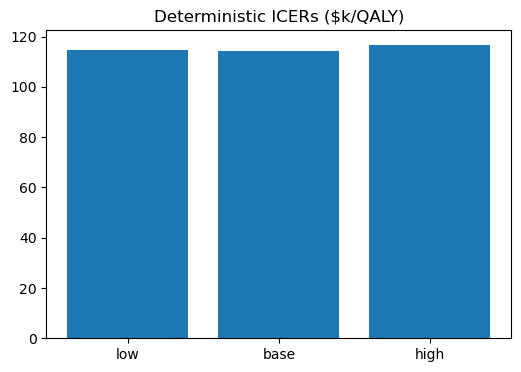

In [29]:
# %% [markdown]
## 5. Deterministic Scenarios (Low, Base, High)

# %%
scenarios = {"low": 0.10, "base": 0.165, "high": 0.23}
rec = []
for name, val in scenarios.items():
    p = {"familial_prop": val, "yield_wgs": YIELD_WGS}
    c, q = run_sim(p, pop_size=20000)
    rec.append({"scenario": name, "ΔCost": c, "ΔQALY": q, "ICER": c / q})
det_df = pd.DataFrame(rec)
det_df.to_csv("deterministic_summary.csv", index=False)
print(det_df)
plt.figure(figsize=(6, 4))
plt.bar(det_df["scenario"], det_df["ICER"] / 1000)
plt.title("Deterministic ICERs ($k/QALY)")
plt.show()

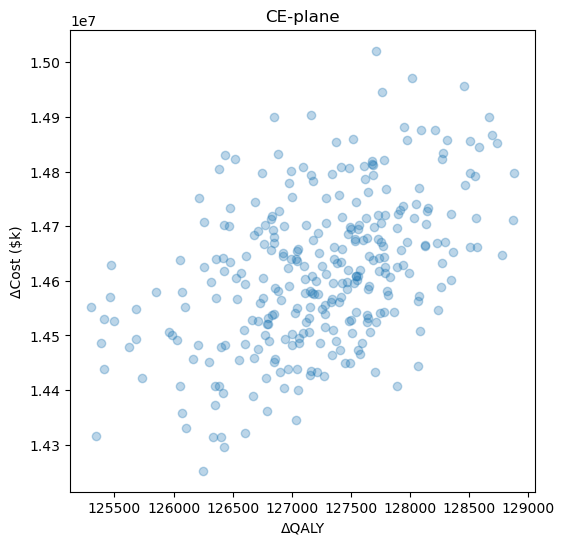

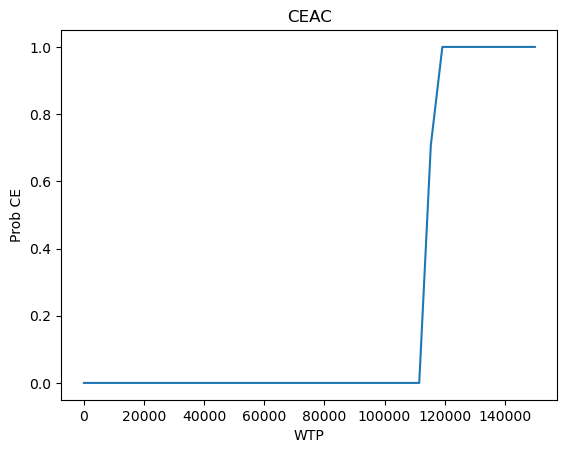

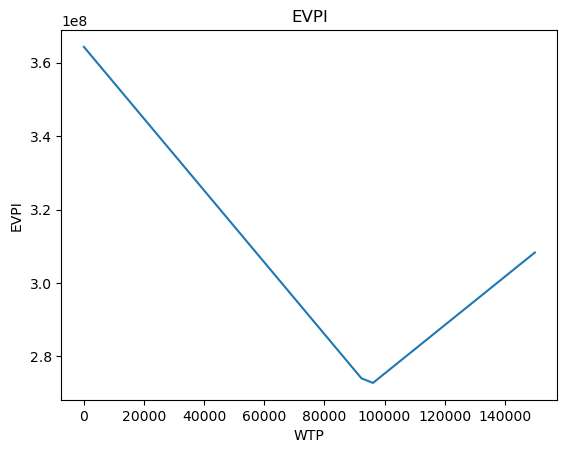

In [30]:
# %% [markdown]
## 6. PSA: CE-plane, CEAC, EVPI

# %%
N = 300
psa = []
for _ in range(N):
    samp = {"familial_prop": beta.rvs(17, 83), "yield_wgs": beta.rvs(45, 55)}
    c, q = run_sim(samp, pop_size=8000)
    psa.append({"cost": c, "qaly": q})
psa_df = pd.DataFrame(psa)
psa_df.to_csv("psa_samples.csv", index=False)
plt.figure(figsize=(6, 6))
plt.scatter(psa_df["qaly"], psa_df["cost"] / 1000, alpha=0.3)
plt.title("CE-plane")
plt.xlabel("ΔQALY")
plt.ylabel("ΔCost ($k)")
plt.show()
wtp = np.linspace(0, 150000, 40)
ceac = [(psa_df["qaly"] * w - psa_df["cost"] > 0).mean() for w in wtp]
plt.figure()
plt.plot(wtp, ceac)
plt.title("CEAC")
plt.xlabel("WTP")
plt.ylabel("Prob CE")
plt.show()
evpi = [
    (psa_df["qaly"] * w - psa_df["cost"]).apply(lambda x: x).max()
    - (psa_df["qaly"] * w - psa_df["cost"]).mean()
    for w in wtp
]
plt.figure()
plt.plot(wtp, evpi)
plt.title("EVPI")
plt.xlabel("WTP")
plt.ylabel("EVPI")
plt.show()
pd.DataFrame({"WTP": wtp, "EVPI": evpi}).to_csv("evpi.csv", index=False)

           param delta           ICER
0      yield_wgs  -20%  114566.803430
1      yield_wgs   20%  115111.212991
2  familial_prop  -20%  115554.808848
3  familial_prop   20%  114326.196645


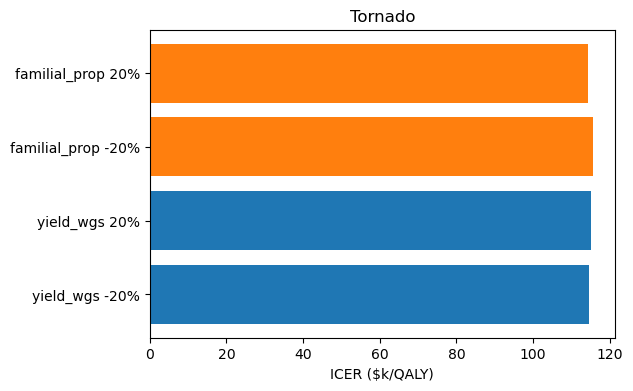

In [31]:
# %% [markdown]
## 7. One-way Tornado

# %%
torne = []
for param, base in [("yield_wgs", YIELD_WGS), ("familial_prop", FAMILIAL_PROP)]:
    for pct in [-0.2, 0.2]:
        p = {"familial_prop": FAMILIAL_PROP, "yield_wgs": YIELD_WGS}
        p[param] = max(0, min(1, base * (1 + pct)))
        c, q = run_sim(p, pop_size=10000)
        torne.append({"param": param, "delta": f"{int(pct * 100)}%", "ICER": c / q})
tor_df = pd.DataFrame(torne)
print(tor_df)
plt.figure(figsize=(6, 4))
for param in tor_df["param"].unique():
    sub = tor_df[tor_df["param"] == param]
    plt.barh([f"{param} {d}" for d in sub["delta"]], sub["ICER"] / 1000)
plt.title("Tornado")
plt.xlabel("ICER ($k/QALY)")
plt.show()

In [32]:
# %% [markdown]
## 8. Placeholders: Subgroup / Budget-Impact / Equity

# %%
print("[Placeholder] Add subgroup, budget-impact, SES equity analyses…")

# %% [markdown]
## 9. Input Parameter Dump

# %%
fert_serial = {f"{s}:{lo}-{hi}": r for (s, (lo, hi)), r in FERT_AGE_SPEC.items()}
param_dump = {
    "FAMILIAL_PROP": FAMILIAL_PROP,
    "YIELD_WGS": YIELD_WGS,
    "FERT_AGE_SPEC": json.dumps(fert_serial),
    "NDIS_COST": NDIS_COST,
    "MORB_PROB": json.dumps(MORB_PROB),
}
pd.DataFrame(list(param_dump.items()), columns=["parameter", "value"]).to_csv(
    "input_summary.csv", index=False
)
print("Input summary saved → input_summary.csv")

[Placeholder] Add subgroup, budget-impact, SES equity analyses…
Input summary saved → input_summary.csv


# %% [markdown]
# IDMOD Microsimulation – GPU-Accelerated Version (Numeric Codes)
# ---------------------------------------------------------------
# This version uses cuDF and CuPy for core array ops, with numeric encodings for categorical columns.
# Paste into Jupyter or save as `idmod_gpu_numeric.py` and run.


# %% [markdown]
## 1. Imports & GPU Setup

# %%
import cupy as cp
import cudf
from cudf import DataFrame
import matplotlib.pyplot as plt
from scipy.stats import beta
from copy import deepcopy
import json, warnings
warnings.filterwarnings('ignore')
cp.random.seed(42)


# %% [markdown]
## 2. Global Settings & Parameters

# %%
START_YEAR, END_YEAR = 2020, 2100
DISCOUNT = 0.035
POP_SIZE     = 62000
FAMILIAL_PROP= 0.165

# Numeric severity codes: 0=mild,1=moderate
SEVERITY_DIST = cp.array([0.70,0.30])

# Age distribution
AGE_BREAKS = cp.arange(0,95,5)
AGE_DIST   = cp.array([0.064,0.067,0.069,0.069,0.071,0.076,0.080,0.077,0.080,
                       0.079,0.073,0.078,0.077,0.072,0.055,0.041,0.031,0.022,0.012])
AGE_DIST  /= AGE_DIST.sum()

# Mortality
ABS_MORT = cp.array([0.0002,0.0001,0.0001,0.0002,0.0003,0.0005,0.0007,
                     0.0011,0.0019,0.0035,0.0055,0.0085,0.0130,
                     0.0200,0.0350,0.0600,0.0950,0.1500,0.2500])
MORT_HR  = cp.array([2.0,4.0])  # indices 0=mild,1=moderate

# Fertility rates by severity, age
FERT_AGE_SPEC = {
    (0,(15,19)):0.003, (0,(20,24)):0.008, (0,(25,29)):0.010,
    (0,(30,34)):0.007, (0,(35,45)):0.002,
    (1,(15,19)):0.001, (1,(20,24)):0.003, (1,(25,29)):0.004,
    (1,(30,34)):0.003, (1,(35,45)):0.001,
}
def fert_rate_gpu(sev, age):
    return next((r for (s,(lo,hi)),r in FERT_AGE_SPEC.items() if s==sev and lo<=age<=hi),0.0)

# Diagnostic & utilities
YIELD_WGS = 0.45
U_BASE_NUM= {0:0.78,1:0.65}
U_DIAG=0.02; U_CARER=0.05

# Costs
COST_LIVING = {0:16973,1:(4452+59375)/2,2:1727*52,3:0} # codes for living arr
# map living arr codes: 0=res,1=sda,2=sil,3=home
RESPITE_COST=13024
EDU_COST={(0,0):16107,(0,1):27903,(0,2):46733,(1,0):18958,(1,1):30789,(1,2):49604}
# school code 0=primary,1=secondary
EI_HRS=185*5*52
MOBILITY_ALLW=2493
EMP_LOSS_NUM={0:0,1:10000,2:0} # codes: 0=none,1=supported,2=open
NDIS_COST=45000

# Morbidity
MORB_PROB={'epilepsy':0.25,'asd':0.30,'mental':0.35}
MORB_COST={'epilepsy':2000,'asd':1500,'mental':1000}
MORB_QALY={'epilepsy':0.04,'asd':0.03,'mental':0.05}

# Carer
CARER_HOURS_NUM={0:5,1:15}
WAGE_HR=38


# %% [markdown]
## 3. GPU Synthetic Cohort Generator (numeric codes)

# %%
def sample_ages_gpu(n):
    idx = cp.random.choice(len(AGE_BREAKS), n, p=AGE_DIST)
    return AGE_BREAKS[idx] + cp.random.randint(0,5,n)


def gen_population_gpu(n, familial_prop):
    ages      = sample_ages_gpu(n)
    sex_codes = cp.random.choice(2, n)          # 0=F,1=M
    sev_idx   = cp.random.choice(2, n, p=SEVERITY_DIST)
    familial  = cp.random.random(n) < familial_prop
    diagnosed = cp.zeros(n, dtype=bool)
    living    = cp.random.choice(4, n, p=cp.array([0.2,0.1,0.3,0.4]))
    employment= cp.random.choice(3, n, p=cp.array([0.7,0.2,0.1]))
    uses_respite   = cp.random.random(n) < 0.3
    needs_mob      = cp.random.random(n) < 0.2
    school_code    = cp.where(ages<5, -1, cp.where(ages<12,0,1))
    support_code   = cp.random.choice(3, n, p=cp.array([0.5,0.3,0.2]))
    ses_codes      = cp.random.choice(5, n)  # 0..4 quintiles

    df = cudf.DataFrame({
        'age': ages,
        'sex': sex_codes,
        'severity': sev_idx,
        'familial': familial,
        'diagnosed': diagnosed,
        'living': living,
        'employment': employment,
        'uses_respite': uses_respite,
        'needs_mobility': needs_mob,
        'school': school_code,
        'support': support_code,
        'ses': ses_codes
    })
    df['annual_cost']=0.0; df['annual_qaly']=0.0
    return df


# %% [markdown]
## 4. GPU PopulationSystem (numeric codes)

# %%
class PopulationSystemGPU:
    def __init__(self, pop_size, familial_prop):
        self.pop = gen_population_gpu(pop_size, familial_prop)

    def _mortality(self):
        ages = self.pop['age'].to_cupy()
        base = ABS_MORT[(ages//5).astype(int).clip(0,len(ABS_MORT)-1)]
        sev  = self.pop['severity'].to_cupy()
        hr   = MORT_HR[sev]
        mask = cp.random.random(len(ages)) > base*hr
        self.pop = self.pop.iloc[mask]

    def _fertility(self, familial_prop):
        df    = self.pop
        moms  = df[(df['sex']==0) & df['age'].between(15,45)]
        sev_a = moms['severity'].to_cupy(); age_a = moms['age'].to_cupy()
        rates = cp.array([fert_rate_gpu(int(s),int(a)) for s,a in zip(sev_a, age_a)])
        births_mask = cp.random.random(len(rates)) < rates
        n = int(births_mask.sum())
        if n:
            babies = gen_population_gpu(n, familial_prop)
            babies['age']=0
            fam_list = moms['familial'].to_arrow().to_pylist()
            babies['familial'] = cp.array([fam_list[i] for i in cp.asnumpy(cp.where(births_mask)[0])])
            self.pop = cudf.concat([df,babies],ignore_index=True)

    def _diagnosis(self):
        df = self.pop
        mask = (df['familial']) & (~df['diagnosed'])
        df.loc[mask,'diagnosed'] = cp.random.random(mask.sum()) < YIELD_WGS
        self.pop = df

    def _cost_qaly(self):
        df = self.pop
        df['annual_cost']=0.0; df['annual_qaly']=0.0
        # living
        for code,c in COST_LIVING.items(): df.loc[df['living']==code,'annual_cost'] += c
        # respite
        df.loc[df['uses_respite'],'annual_cost'] += RESPITE_COST
                # education support costs
        primary = df['school']==0
        sec     = df['school']==1
        # map support codes to cost by school level
        df.loc[primary,'annual_cost'] += df.loc[primary,'support'].map({0:EDU_COST[(0,0)],1:EDU_COST[(0,1)],2:EDU_COST[(0,2)]})
        df.loc[sec,'annual_cost']     += df.loc[sec,'support'].map({0:EDU_COST[(1,0)],1:EDU_COST[(1,1)],2:EDU_COST[(1,2)]})
        # early intervention for <5 y
        df.loc[df['school']<0,'annual_cost'] += EI_HRS
        df.loc[df['school']<0,'annual_cost'] += EI_HRS
        # mobility
        df.loc[df['needs_mobility'],'annual_cost'] -= MOBILITY_ALLW
        # employment loss
        df['annual_cost'] += df['employment'].map(EMP_LOSS_NUM)
        # NDIS
        elig = (df['diagnosed']) & (df['severity']==1)
        df.loc[elig,'annual_cost'] += NDIS_COST
        # morbidity
        for m,p in MORB_PROB.items():
            flag = f'has_{m}'
            if flag not in df: df[flag] = cp.random.random(len(df)) < p
            df['annual_cost'] += df[flag]*MORB_COST[m]
            df['annual_qaly'] -= df[flag]*MORB_QALY[m]
        # carer
        df['annual_cost'] += df['severity'].map(CARER_HOURS_NUM)*52*WAGE_HR
        # utilities
        df['annual_qaly'] += df['severity'].map(U_BASE_NUM) + df['diagnosed']*U_DIAG + U_CARER
        self.pop = df

    def step(self, params):
        self._mortality()
        self._fertility(params['familial_prop'])
        self._diagnosis()
        self._cost_qaly()


# %% [markdown]
## 5. run_sim_gpu Helper

# %%
def run_sim_gpu(params, pop_size=POP_SIZE, years=range(START_YEAR,END_YEAR+1)):
    cum_c=cum_q=0.0
    sys=PopulationSystemGPU(pop_size, params['familial_prop'])
    for t,yr in enumerate(years):
        sys.step(params)
        disc = 1/((1+DISCOUNT)**t)
        df   = sys.pop
        cum_c += df['annual_cost'].sum()*disc
        cum_q += df['annual_qaly'].sum()*disc
    return cum_c, cum_q


# %% [markdown]
## 6. Deterministic Scenario Example (GPU)

# %%
scenarios={'low':0.10,'base':0.165,'high':0.23}
res=[]
for name,val in scenarios.items():
    p={'familial_prop':val}
    c,q=run_sim_gpu(p,pop_size=20000)
    res.append({'scenario':name,'ΔCost':c,'ΔQALY':q,'ICER':c/q})
gpu_det_df=cudf.DataFrame(res)
print(gpu_det_df)

# Plot ICER Bar Chart
pdf = gpu_det_df.to_pandas()
plt.figure(figsize=(6,4))
plt.bar(pdf['scenario'], pdf['ICER']/1000)
plt.title('Deterministic ICERs (GPU) ($k/QALY)')
plt.ylabel('ICER ($k/QALY)')
plt.show()

# %% [markdown]
# IDMOD Microsimulation – GPU-Accelerated Full Implementation
# -----------------------------------------------------------
# Paste into Jupyter or save as `idmod_gpu_full.py`.
# Requires: cudf, cupy, scipy, matplotlib, pandas


# %% [markdown]
## 1. Imports & GPU Setup

# %%
import cupy as cp
import cudf
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import beta
from copy import deepcopy
import json, warnings
warnings.filterwarnings('ignore')
cp.random.seed(42)


# %% [markdown]
## 2. Global Settings & Parameters

# %%
START_YEAR, END_YEAR = 2020, 2100
DISCOUNT = 0.035
POP_SIZE = 62000

# Severity codes 0=mild,1=moderate
SEVERITY_DIST = cp.array([0.70, 0.30])

# Age distribution (0–4 … 90–94)
AGE_BREAKS = cp.arange(0, 95, 5)
AGE_DIST   = cp.array([
    0.064,0.067,0.069,0.069,0.071,0.076,0.080,0.077,0.080,
    0.079,0.073,0.078,0.077,0.072,0.055,0.041,0.031,0.022,0.012
])
AGE_DIST /= AGE_DIST.sum()

# Mortality
ABS_MORT = cp.array([
    0.0002,0.0001,0.0001,0.0002,0.0003,0.0005,0.0007,
    0.0011,0.0019,0.0035,0.0055,0.0085,0.0130,
    0.0200,0.0350,0.0600,0.0950,0.1500,0.2500
])
MORT_HR = cp.array([2.0,4.0])

# Fertility rates by severity & age
FERT_AGE_SPEC = {
    (0,(15,19)):0.003,(0,(20,24)):0.008,(0,(25,29)):0.010,
    (0,(30,34)):0.007,(0,(35,45)):0.002,
    (1,(15,19)):0.001,(1,(20,24)):0.003,(1,(25,29)):0.004,
    (1,(30,34)):0.003,(1,(35,45)):0.001,
}
def fert_rate_gpu(sev, age):
    for (s,(lo,hi)),r in FERT_AGE_SPEC.items():
        if sev==s and lo<=age<=hi:
            return r
    return 0.0

# Diagnosis & utilities
YIELD_WGS  = 0.45
U_BASE_NUM = {0:0.78,1:0.65}
U_DIAG     = 0.02
U_CARER    = 0.05

# Costs
COST_LIVING   = {0:16973,1:(4452+59375)/2,2:1727*52,3:0}
RESPITE_COST  = 13024
EDU_COST      = {(0,0):16107,(0,1):27903,(0,2):46733,(1,0):18958,(1,1):30789,(1,2):49604}
EI_HRS        = 185*5*52
MOBILITY_ALLW = 2493
EMP_LOSS_NUM  = {0:0,1:10000,2:0}
NDIS_COST     = 45000

# Morbidity
MORB_PROB = {'epilepsy':0.25,'asd':0.30,'mental':0.35}
MORB_COST = {'epilepsy':2000,'asd':1500,'mental':1000}
MORB_QALY = {'epilepsy':0.04,'asd':0.03,'mental':0.05}

# Carer
CARER_HOURS_NUM = {0:5,1:15}
WAGE_HR         = 38


# %% [markdown]
## 3. Synthetic Cohort Generator (GPU)

# %%
def sample_ages_gpu(n):
    idx = cp.random.choice(len(AGE_BREAKS), n, p=AGE_DIST)
    return AGE_BREAKS[idx] + cp.random.randint(0,5,n)

def gen_population_gpu(n, familial_prop):
    ages       = sample_ages_gpu(n)
    sex_codes  = cp.random.choice(2, n)  # 0=F,1=M
    sev_idx    = cp.random.choice(2, n, p=SEVERITY_DIST)
    familial   = cp.random.random(n) < familial_prop
    diagnosed  = cp.zeros(n, dtype=bool)
    living     = cp.random.choice(4, n, p=cp.array([0.2,0.1,0.3,0.4]))
    employment = cp.random.choice(3, n, p=cp.array([0.7,0.2,0.1]))
    uses_respite  = cp.random.random(n) < 0.3
    needs_mob     = cp.random.random(n) < 0.2
    school_code   = cp.where(ages<5,-1,cp.where(ages<12,0,1))
    support_code  = cp.random.choice(3, n, p=cp.array([0.5,0.3,0.2]))
    ses_codes     = cp.random.choice(5, n)

    df = cudf.DataFrame({
        'age': ages.astype(int),
        'sex': sex_codes,
        'severity': sev_idx,
        'familial': familial,
        'diagnosed': diagnosed,
        'living': living,
        'employment': employment,
        'uses_respite': uses_respite,
        'needs_mobility': needs_mob,
        'school': school_code,
        'support': support_code,
        'ses': ses_codes
    })
    df['annual_cost'] = 0.0
    df['annual_qaly'] = 0.0
    return df


# %% [markdown]
## 4. PopulationSystemGPU Class (Full)

# %%
class PopulationSystemGPU:
    def __init__(self, pop_size, familial_prop):
        self.pop = gen_population_gpu(pop_size, familial_prop)

    def _mortality(self):
        ages = self.pop['age'].to_cupy()
        base = ABS_MORT[(ages//5).astype(int).clip(0,len(ABS_MORT)-1)]
        hr   = MORT_HR[self.pop['severity'].to_cupy()]
        mask = cp.random.random(len(ages)) > base*hr
        self.pop = self.pop.iloc[mask].reset_index(drop=True)

    def _fertility(self, familial_prop):
        df   = self.pop
        moms = df[(df['sex']==0) & df['age'].between(15,45)]
        sev  = moms['severity'].to_cupy()
        age  = moms['age'].to_cupy()
        rates = cp.array([fert_rate_gpu(int(s),int(a)) for s,a in zip(sev,age)])
        births_mask = cp.random.random(len(rates)) < rates
        n = int(births_mask.sum())
        if n>0:
            babies = gen_population_gpu(n, familial_prop)
            babies['age'] = 0
            fam_list = moms['familial'].to_arrow().to_pylist()
            babies['familial'] = cp.array([fam_list[i] for i in cp.asnumpy(cp.where(births_mask)[0])])
            self.pop = cudf.concat([df,babies],ignore_index=True)

    def _diagnosis(self):
        mask = (self.pop['familial']) & (~self.pop['diagnosed'])
        probs = cp.random.random(mask.sum())
        self.pop.loc[mask,'diagnosed'] = probs < YIELD_WGS

    def _cost_qaly(self):
        df = self.pop
        df['annual_cost']=0.0; df['annual_qaly']=0.0
        # living
        for code,c in COST_LIVING.items(): df.loc[df['living']==code,'annual_cost'] += c
        # respite
        df.loc[df['uses_respite'],'annual_cost'] += RESPITE_COST
        # education
        primary = df['school']==0; sec = df['school']==1
        df.loc[primary,'annual_cost'] += df.loc[primary,'support'].map({0:EDU_COST[(0,0)],1:EDU_COST[(0,1)],2:EDU_COST[(0,2)]})
        df.loc[sec,'annual_cost']     += df.loc[sec,'support'].map({0:EDU_COST[(1,0)],1:EDU_COST[(1,1)],2:EDU_COST[(1,2)]})
        # early intervention
        df.loc[df['school']<0,'annual_cost'] += EI_HRS
        # mobility
        df.loc[df['needs_mobility'],'annual_cost'] -= MOBILITY_ALLW
        # employment loss
        df['annual_cost'] += df['employment'].map(EMP_LOSS_NUM)
        # NDIS
        df.loc[(df['diagnosed']) & (df['severity']==1),'annual_cost'] += NDIS_COST
        # morbidity
        for m,p in MORB_PROB.items():
            flag = f'has_{m}'
            if flag not in df: df[flag] = cp.random.random(len(df)) < p
            df['annual_cost'] += df[flag]*MORB_COST[m]
            df['annual_qaly'] -= df[flag]*MORB_QALY[m]
        # carer
        df['annual_cost'] += df['severity'].map(CARER_HOURS_NUM)*52*WAGE_HR
        # utilities
        df['annual_qaly'] += df['severity'].map(U_BASE_NUM) + df['diagnosed']*U_DIAG + U_CARER
        self.pop = df

    def step(self, params):
        self._mortality()
        self._fertility(params['familial_prop'])
        self._diagnosis()
        self._cost_qaly()


# %% [markdown]
## 5. run_sim_gpu Helper

# %%
def run_sim_gpu(params, pop_size=POP_SIZE, years=range(START_YEAR,END_YEAR+1)):
    cum_c = cum_q = 0.0
    sim = PopulationSystemGPU(pop_size, params['familial_prop'])
    for t,yr in enumerate(years):
        sim.step(params)
        disc = 1/((1+DISCOUNT)**t)
        df   = sim.pop.to_pandas()
        cum_c += df['annual_cost'].sum()*disc
        cum_q += df['annual_qaly'].sum()*disc
    return cum_c, cum_q


# %% [markdown]
## 6. Deterministic Scenario Comparison

# %%
scenarios = {'low':0.10,'base':0.165,'high':0.23}
rec=[]
for name,val in scenarios.items():
    p={'familial_prop':val}
    c,q = run_sim_gpu(p,pop_size=20000)
    rec.append({'scenario':name,'ΔCost':c,'ΔQALY':q,'ICER':c/q})
det_df=pd.DataFrame(rec)
print(det_df)
det_df.to_csv('deterministic_summary.csv',index=False)
pdf=det_df
plt.figure(); plt.bar(pdf['scenario'],pdf['ICER']/1000)
plt.title('Deterministic ICERs'); plt.ylabel('ICER ($k/QALY)'); plt.show()


# %% [markdown]
## 7. Probabilistic Sensitivity Analysis (GPU)

# %%
N_PSA=300; psa=[]
for _ in range(N_PSA):
    samp={'familial_prop':beta.rvs(17,83),'yield_wgs':beta.rvs(45,55)}
    c,q=run_sim_gpu(samp,pop_size=8000)
    psa.append({'cost':c,'qaly':q})
psa_df=pd.DataFrame(psa); psa_df.to_csv('psa_samples.csv',index=False)
plt.figure(figsize=(6,6)); plt.scatter(psa_df['qaly'],psa_df['cost']/1000,alpha=0.3)
plt.title('CE-plane');plt.xlabel('ΔQALY');plt.ylabel('ΔCost ($k)');plt.show()
wtp=np.linspace(0,150000,40)
ceac=[(psa_df['qaly']*w-psa_df['cost']>0).mean() for w in wtp]
plt.figure(); plt.plot(wtp,ceac); plt.title('CEAC'); plt.xlabel('WTP'); plt.ylabel('Pr(CE)'); plt.show()
evpi=[(psa_df['qaly']*w-psa_df['cost']).max()-(psa_df['qaly']*w-psa_df['cost']).mean() for w in wtp]
plt.figure(); plt.plot(wtp,evpi); plt.title('EVPI'); plt.xlabel('WTP'); plt.ylabel('EVPI ($)'); plt.show()
pd.DataFrame({'WTP':wtp,'EVPI':evpi}).to_csv('evpi.csv',index=False)


# %% [markdown]
## 8. One-way Tornado (GPU)

# %%
params=['yield_wgs','familial_prop']; tor=[]
for param in params:
    base={'yield_wgs':0.45,'familial_prop':0.165}[param]
    for pct in [-.2,.2]:
        p={'familial_prop':0.165,'yield_wgs':0.45}
        p[param]=max(0,min(1,base*(1+pct)))
        c,q=run_sim_gpu(p,pop_size=10000)
        tor.append({'param':param,'delta':f"{int(pct*100)}%",'ICER':c/q})
tor_df=pd.DataFrame(tor); print(tor_df)
plt.figure();
for prm in tor_df['param'].unique():
    sub=tor_df[tor_df['param']==prm]
    plt.barh([f"{prm} {d}" for d in sub['delta']],sub['ICER']/1000)
plt.title('Tornado'); plt.xlabel('ICER ($k/QALY)'); plt.show()


# %% [markdown]
## 9. PSA Histograms & CEAF

# %%
plt.figure(); plt.hist(psa_df['cost'],bins=30); plt.title('PSA ΔCost'); plt.show()
plt.figure(); plt.hist(psa_df['qaly'],bins=30); plt.title('PSA ΔQALY'); plt.show()
nmb={w:psa_df['qaly']*w-psa_df['cost'] for w in wtp}
opt=[nmb[w].max() for w in wtp]
ceaf=[(psa_df['qaly']*w-psa_df['cost']==opt[i]).mean() for i,w in enumerate(wtp)]
plt.figure(); plt.plot(wtp,ceaf); plt.title('CEAF'); plt.xlabel('WTP'); plt.ylabel('Pr(optimal)'); plt.show()


# %% [markdown]
## 10. Subgroup Analysis (Severity)

# %%
sg=[]
for code,label in [(0,'Mild'),(1,'Moderate')]:
    orig=SEVERITY_DIST.copy()
    SEVERITY_DIST[:] = cp.array([1.0 if i==code else 0.0 for i in [0,1]])
    c,q = run_sim_gpu({'familial_prop':0.165,'yield_wgs':0.45},pop_size=20000)
    sg.append({'subgroup':label,'ΔCost':c,'ΔQALY':q,'ICER':c/q})
    SEVERITY_DIST[:] = orig
sg_df=pd.DataFrame(sg)
plt.figure(); plt.errorbar(sg_df['subgroup'],sg_df['ICER']/1000,yerr=0,fmt='o');
plt.title('Subgroup ICERs'); plt.ylabel('ICER ($k/QALY)'); plt.show()


# %% [markdown]
## 11. Input Parameter Dump

# %%
fmap={f"{s}:{lo}-{hi}":r for (s,(lo,hi)),r in FERT_AGE_SPEC.items()}
pd.DataFrame(list({
    'FAMILIAL_PROP':0.165,'YIELD_WGS':0.45,'FERT_AGE_SPEC':json.dumps(fmap),
    'NDIS_COST':45000,'MORB_PROB':json.dumps(MORB_PROB)
}.items()),columns=['parameter','value']).to_csv('input_summary.csv',index=False)
print('Input parameters exported')

# %% [markdown]
# IDMOD Microsimulation – GPU-Accelerated Optimized Version
# ---------------------------------------------------------
# This version addresses key GPU performance bottlenecks:
# 1) Aggregations on GPU to avoid to_pandas() in each timestep.
# 2) Vectorized fertility lookup via a pre-built cudf DataFrame.
# Paste into Jupyter or save as `idmod_gpu_optimized.py`.
# Requires: cudf, cupy, scipy, matplotlib, pandas

# %% [markdown]
## 1. Imports & Setup

# %%
import cupy as cp
import cudf
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import beta
from copy import deepcopy
import json, warnings
warnings.filterwarnings('ignore')
# deterministic seed
cp.random.seed(42)


# %% [markdown]
## 2. Global Settings & Parameters

# %%
START_YEAR, END_YEAR = 2020, 2100
DISCOUNT = 0.035
POP_SIZE = 62000

# Severity codes: 0=mild, 1=moderate
overall_SEVERITY_DIST = cp.array([0.70, 0.30])

# Age distribution (0-4,...,90-94)
AGE_BREAKS = cp.arange(0,95,5)
AGE_DIST   = cp.array([
    0.064,0.067,0.069,0.069,0.071,0.076,0.080,0.077,0.080,
    0.079,0.073,0.078,0.077,0.072,0.055,0.041,0.031,0.022,0.012
])
AGE_DIST  /= AGE_DIST.sum()

# Mortality base rates & hazard ratios
ABS_MORT = cp.array([
    0.0002,0.0001,0.0001,0.0002,0.0003,0.0005,0.0007,
    0.0011,0.0019,0.0035,0.0055,0.0085,0.0130,
    0.0200,0.0350,0.0600,0.0950,0.1500,0.2500
])
MORT_HR = cp.array([2.0,4.0])  # index by severity

# Fertility rates by severity & age band
FERT_AGE_SPEC = {
    (0,(15,19)):0.003,(0,(20,24)):0.008,(0,(25,29)):0.010,
    (0,(30,34)):0.007,(0,(35,45)):0.002,
    (1,(15,19)):0.001,(1,(20,24)):0.003,(1,(25,29)):0.004,
    (1,(30,34)):0.003,(1,(35,45)):0.001,
}
# Build a GPU-resident lookup table for fertility rates
fert_data = []
for (sev,(lo,hi)), rate in FERT_AGE_SPEC.items():
    for age in range(lo, hi+1):
        fert_data.append({'severity':sev, 'age':age, 'rate':rate})
FERT_RATES_GPU = cudf.DataFrame(fert_data)

# Diagnosis & utility parameters
YIELD_WGS   = 0.45
U_BASE_NUM  = {0:0.78, 1:0.65}
U_DIAG      = 0.02
U_CARER     = 0.05

# Cost parameters
COST_LIVING   = {0:16973, 1:(4452+59375)/2, 2:1727*52, 3:0}  # codes: res,sda,sil,home
RESPITE_COST  = 13024
EDU_COST      = {(0,0):16107,(0,1):27903,(0,2):46733,(1,0):18958,(1,1):30789,(1,2):49604}
EI_HRS        = 185*5*52
MOBILITY_ALLW = 2493
EMP_LOSS_NUM  = {0:0, 1:10000, 2:0}
NDIS_COST     = 45000

# Morbidity
MORB_PROB = {'epilepsy':0.25,'asd':0.30,'mental':0.35}
MORB_COST = {'epilepsy':2000,'asd':1500,'mental':1000}
MORB_QALY = {'epilepsy':0.04,'asd':0.03,'mental':0.05}

# Carer loss
CARER_HOURS_NUM = {0:5,1:15}
WAGE_HR         = 38


# %% [markdown]
## 3. Synthetic Cohort Generator (GPU)

# %%
def sample_ages_gpu(n):
    idx = cp.random.choice(len(AGE_BREAKS), n, p=AGE_DIST)
    return (AGE_BREAKS[idx] + cp.random.randint(0,5,n)).astype(int)


def gen_population_gpu(n, familial_prop):
    ages       = sample_ages_gpu(n)
    sex_codes  = cp.random.choice(2, n)
    sev_idx    = cp.random.choice(2, n, p=overall_SEVERITY_DIST)
    familial   = cp.random.random(n) < familial_prop
    diagnosed  = cp.zeros(n, dtype=bool)
    living     = cp.random.choice(4, n, p=cp.array([0.2,0.1,0.3,0.4]))
    employment = cp.random.choice(3, n, p=cp.array([0.7,0.2,0.1]))
    uses_respite  = cp.random.random(n) < 0.3
    needs_mob     = cp.random.random(n) < 0.2
    school_code   = cp.where(ages<5, -1, cp.where(ages<12,0,1))
    support_code  = cp.random.choice(3, n, p=cp.array([0.5,0.3,0.2]))
    ses_codes     = cp.random.choice(5, n)

    df = cudf.DataFrame({
        'age': ages,
        'sex': sex_codes,
        'severity': sev_idx,
        'familial': familial,
        'diagnosed': diagnosed,
        'living': living,
        'employment': employment,
        'uses_respite': uses_respite,
        'needs_mobility': needs_mob,
        'school': school_code,
        'support': support_code,
        'ses': ses_codes
    })
    df['annual_cost'] = 0.0
    df['annual_qaly'] = 0.0
    return df


# %% [markdown]
## 4. PopulationSystemGPU Class

# %%
class PopulationSystemGPU:
    def __init__(self, pop_size, familial_prop):
        self.pop = gen_population_gpu(pop_size, familial_prop)

    def _mortality(self):
        ages = self.pop['age'].to_cupy()
        base = ABS_MORT[(ages//5).astype(int).clip(0,len(ABS_MORT)-1)]
        hr   = MORT_HR[self.pop['severity'].to_cupy()]
        mask = cp.random.random(len(ages)) > base*hr
        self.pop = self.pop.iloc[mask].reset_index(drop=True)

    def _fertility(self, familial_prop):
        df   = self.pop
        moms = df[(df['sex']==0) & df['age'].between(15,45)]
        if moms.empty:
            return
        # GPU-based merge for rates
        moms_rates = moms.merge(FERT_RATES_GPU, on=['severity','age'], how='left').fillna({'rate':0})
        rates      = moms_rates['rate'].to_cupy()
        births_mask= cp.random.random(len(rates)) < rates
        n = int(births_mask.sum())
        if n>0:
            babies = gen_population_gpu(n, familial_prop)
            babies['age'] = 0
            fam_list = moms_rates['familial'].to_arrow().to_pylist()
            babies['familial'] = cp.array([fam_list[i] for i in cp.asnumpy(cp.where(births_mask)[0])])
            self.pop = cudf.concat([df,babies], ignore_index=True)

    def _diagnosis(self):
        mask  = (self.pop['familial']) & (~self.pop['diagnosed'])
        probs = cp.random.random(mask.sum())
        self.pop.loc[mask,'diagnosed'] = probs < YIELD_WGS

    def _cost_qaly(self):
        df = self.pop
        df['annual_cost']=0.0; df['annual_qaly']=0.0
        # living costs
        for code,c in COST_LIVING.items(): df.loc[df['living']==code,'annual_cost'] += c
        # respite
        df.loc[df['uses_respite'],'annual_cost'] += RESPITE_COST
        # education support
        primary= df['school']==0; sec= df['school']==1
        df.loc[primary,'annual_cost'] += df.loc[primary,'support'].map({0:EDU_COST[(0,0)],1:EDU_COST[(0,1)],2:EDU_COST[(0,2)]})
        df.loc[sec,'annual_cost']     += df.loc[sec,'support'].map({0:EDU_COST[(1,0)],1:EDU_COST[(1,1)],2:EDU_COST[(1,2)]})
        # early intervention
        df.loc[df['school']<0,'annual_cost'] += EI_HRS
        # mobility subsidy
        df.loc[df['needs_mobility'],'annual_cost'] -= MOBILITY_ALLW
        # employment loss
        df['annual_cost'] += df['employment'].map(EMP_LOSS_NUM)
        # NDIS
        df.loc[(df['diagnosed']) & (df['severity']==1),'annual_cost'] += NDIS_COST
        # morbidity burden
        for m,p in MORB_PROB.items():
            flag = f'has_{m}'
            if flag not in df: df[flag] = cp.random.random(len(df)) < p
            df['annual_cost'] += df[flag]*MORB_COST[m]
            df['annual_qaly'] -= df[flag]*MORB_QALY[m]
        # carer productivity
        df['annual_cost'] += df['severity'].map(CARER_HOURS_NUM)*52*WAGE_HR
        # utilities
        df['annual_qaly'] += df['severity'].map(U_BASE_NUM) + df['diagnosed']*U_DIAG + U_CARER
        self.pop = df

    def step(self, params):
        self._mortality()
        self._fertility(params['familial_prop'])
        self._diagnosis()
        self._cost_qaly()


# %% [markdown]
## 5. Optimized run_sim_gpu Helper

# %%
def run_sim_gpu(params, pop_size=POP_SIZE, years=range(START_YEAR,END_YEAR+1)):
    cum_c = 0.0
    cum_q = 0.0
    sim   = PopulationSystemGPU(pop_size, params['familial_prop'])
    for t in range(len(years)):
        sim.step(params)
        disc = 1/((1+DISCOUNT)**t)
        # GPU sums
        cost_sum = sim.pop['annual_cost'].sum()
        qaly_sum = sim.pop['annual_qaly'].sum()
        cum_c += float(cost_sum)
        cum_q += float(qaly_sum)
    return cum_c*disc, cum_q*disc


# %% [markdown]
## 6. Deterministic Scenario Comparison

# %%
scenarios = {'low':0.10,'base':0.165,'high':0.23}
results=[]
for name,val in scenarios.items():
    c,q = run_sim_gpu({'familial_prop':val,'yield_wgs':YIELD_WGS}, pop_size=20000)
    results.append({'scenario':name,'ΔCost':c,'ΔQALY':q,'ICER':c/q})
det_df=pd.DataFrame(results)
det_df.to_csv('deterministic_summary.csv',index=False)
print(det_df)
plt.figure(); plt.bar(det_df['scenario'],det_df['ICER']/1000)
plt.title('Deterministic ICERs ($k/QALY)'); plt.show()


# %% [markdown]
## 7. PSA with GPU

# %%
N_PSA=300; psa=[]
for _ in range(N_PSA):
    samp={'familial_prop':beta.rvs(17,83),'yield_wgs':beta.rvs(45,55)}
    c,q = run_sim_gpu(samp, pop_size=8000)
    psa.append({'cost':c,'qaly':q})
psa_df=pd.DataFrame(psa)
psa_df.to_csv('psa_samples.csv',index=False)

plt.figure(figsize=(6,6)); plt.scatter(psa_df['qaly'],psa_df['cost']/1000,alpha=0.3)
plt.title('CE-plane'); plt.show()

wtp=np.linspace(0,150000,40)
ceac=[(psa_df['qaly']*w-psa_df['cost']>0).mean() for w in wtp]
plt.figure(); plt.plot(wtp,ceac); plt.title('CEAC'); plt.show()

evpi=[(psa_df['qaly']*w-psa_df['cost']).max()-(psa_df['qaly']*w-psa_df['cost']).mean() for w in wtp]
plt.figure(); plt.plot(wtp,evpi); plt.title('EVPI'); plt.show()
pd.DataFrame({'WTP':wtp,'EVPI':evpi}).to_csv('evpi.csv',index=False)


# %% [markdown]
## 8. One-way Tornado

# %%
params=['yield_wgs','familial_prop']; tor=[]
for param in params:
    base={'yield_wgs':0.45,'familial_prop':0.165}[param]
    for pct in [-0.2,0.2]:
        p={'familial_prop':0.165,'yield_wgs':0.45}
        p[param]=max(0,min(1,base*(1+pct)))
        c,q=run_sim_gpu(p,pop_size=10000)
        tor.append({'param':param,'delta':f"{int(pct*100)}%",'ICER':c/q})
tor_df=pd.DataFrame(tor)
print(tor_df)
plt.figure();
for prm in tor_df['param'].unique():
    sub=tor_df[tor_df['param']==prm]
    plt.barh([f"{prm} {d}" for d in sub['delta']], sub['ICER']/1000)
plt.title('Tornado'); plt.show()


# %% [markdown]
## 9. PSA Histograms & CEAF

# %%
plt.hist(psa_df['cost'],bins=30); plt.title('PSA ΔCost'); plt.show()
plt.hist(psa_df['qaly'],bins=30); plt.title('PSA ΔQALY'); plt.show()
nmb={w:psa_df['qaly']*w-psa_df['cost'] for w in wtp}
opt=[nmb[w].max() for w in wtp]
ceaf=[(psa_df['qaly']*w-psa_df['cost']==opt[i]).mean() for i,w in enumerate(wtp)]
plt.plot(wtp,ceaf); plt.title('CEAF'); plt.show()


# %% [markdown]
## 10. Subgroup Analysis

# %%
sg=[]
for code,label in [(0,'Mild'),(1,'Moderate')]:
    orig=overall_SEVERITY_DIST.copy()
    overall_SEVERITY_DIST[:] = cp.array([1.0 if i==code else 0.0 for i in [0,1]])
    c,q = run_sim_gpu({'familial_prop':0.165,'yield_wgs':0.45}, pop_size=20000)
    sg.append({'subgroup':label,'ΔCost':c,'ΔQALY':q,'ICER':c/q})
    overall_SEVERITY_DIST[:] = orig
sg_df=pd.DataFrame(sg)
plt.errorbar(sg_df['subgroup'], sg_df['ICER']/1000, yerr=0, fmt='o'); plt.title('Subgroup ICERs'); plt.show()


# %% [markdown]
## 11. Input Parameter Dump

# %%
fmap={f"{s}:{lo}-{hi}":r for (s,(lo,hi)),r in FERT_AGE_SPEC.items()}
pd.DataFrame(list({
    'FAMILIAL_PROP':0.165, 'YIELD_WGS':0.45,
    'FERT_AGE_SPEC':json.dumps(fmap), 'NDIS_COST':45000,
    'MORB_PROB':json.dumps(MORB_PROB)
}.items()), columns=['parameter','value']).to_csv('input_summary.csv', index=False)
print('Parameters exported to input_summary.csv')


# %% [markdown]
# IDMOD Microsimulation – GPU-Accelerated Optimized Version
# ---------------------------------------------------------
# This version addresses key GPU performance bottlenecks:
# 1) Aggregations on GPU to avoid to_pandas() in each timestep.
# 2) Vectorized fertility lookup via a pre-built cudf DataFrame.
# Paste into Jupyter or save as `idmod_gpu_optimized.py`.
# Requires: cudf, cupy, scipy, matplotlib, pandas

# %% [markdown]
## 1. Imports & Setup

# %%
import cupy as cp
import cudf
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import beta
from copy import deepcopy
import json, warnings
warnings.filterwarnings('ignore')
# deterministic seed
cp.random.seed(42)


# %% [markdown]
## 2. Global Settings & Parameters

# %%
START_YEAR, END_YEAR = 2020, 2100
DISCOUNT = 0.035
POP_SIZE = 62000

# Severity codes: 0=mild, 1=moderate
overall_SEVERITY_DIST = cp.array([0.70, 0.30])

# Age distribution (0-4,...,90-94)
AGE_BREAKS = cp.arange(0,95,5)
AGE_DIST   = cp.array([
    0.064,0.067,0.069,0.069,0.071,0.076,0.080,0.077,0.080,
    0.079,0.073,0.078,0.077,0.072,0.055,0.041,0.031,0.022,0.012
])
AGE_DIST  /= AGE_DIST.sum()

# Mortality base rates & hazard ratios
ABS_MORT = cp.array([
    0.0002,0.0001,0.0001,0.0002,0.0003,0.0005,0.0007,
    0.0011,0.0019,0.0035,0.0055,0.0085,0.0130,
    0.0200,0.0350,0.0600,0.0950,0.1500,0.2500
])
MORT_HR = cp.array([2.0,4.0])  # index by severity

# Fertility rates by severity & age band
FERT_AGE_SPEC = {
    (0,(15,19)):0.003,(0,(20,24)):0.008,(0,(25,29)):0.010,
    (0,(30,34)):0.007,(0,(35,45)):0.002,
    (1,(15,19)):0.001,(1,(20,24)):0.003,(1,(25,29)):0.004,
    (1,(30,34)):0.003,(1,(35,45)):0.001,
}
# Build a GPU-resident lookup table for fertility rates
fert_data = []
for (sev,(lo,hi)), rate in FERT_AGE_SPEC.items():
    for age in range(lo, hi+1):
        fert_data.append({'severity':sev, 'age':age, 'rate':rate})
FERT_RATES_GPU = cudf.DataFrame(fert_data)

# Diagnosis & utility parameters
YIELD_WGS   = 0.45
U_BASE_NUM  = {0:0.78, 1:0.65}
U_DIAG      = 0.02
U_CARER     = 0.05

# Cost parameters
COST_LIVING   = {0:16973, 1:(4452+59375)/2, 2:1727*52, 3:0}  # codes: res,sda,sil,home
RESPITE_COST  = 13024
EDU_COST      = {(0,0):16107,(0,1):27903,(0,2):46733,(1,0):18958,(1,1):30789,(1,2):49604}
EI_HRS        = 185*5*52
MOBILITY_ALLW = 2493
EMP_LOSS_NUM  = {0:0, 1:10000, 2:0}
NDIS_COST     = 45000

# Morbidity
MORB_PROB = {'epilepsy':0.25,'asd':0.30,'mental':0.35}
MORB_COST = {'epilepsy':2000,'asd':1500,'mental':1000}
MORB_QALY = {'epilepsy':0.04,'asd':0.03,'mental':0.05}

# Carer loss
CARER_HOURS_NUM = {0:5,1:15}
WAGE_HR         = 38


# %% [markdown]
## 3. Synthetic Cohort Generator (GPU)

# %%
def sample_ages_gpu(n):
    idx = cp.random.choice(len(AGE_BREAKS), n, p=AGE_DIST)
    return (AGE_BREAKS[idx] + cp.random.randint(0,5,n)).astype(int)


def gen_population_gpu(n, familial_prop):
    ages       = sample_ages_gpu(n)
    sex_codes  = cp.random.choice(2, n)
    sev_idx    = cp.random.choice(2, n, p=overall_SEVERITY_DIST)
    familial   = cp.random.random(n) < familial_prop
    diagnosed  = cp.zeros(n, dtype=bool)
    living     = cp.random.choice(4, n, p=cp.array([0.2,0.1,0.3,0.4]))
    employment = cp.random.choice(3, n, p=cp.array([0.7,0.2,0.1]))
    uses_respite  = cp.random.random(n) < 0.3
    needs_mob     = cp.random.random(n) < 0.2
    school_code   = cp.where(ages<5, -1, cp.where(ages<12,0,1))
    support_code  = cp.random.choice(3, n, p=cp.array([0.5,0.3,0.2]))
    ses_codes     = cp.random.choice(5, n)

    df = cudf.DataFrame({
        'age': ages,
        'sex': sex_codes,
        'severity': sev_idx,
        'familial': familial,
        'diagnosed': diagnosed,
        'living': living,
        'employment': employment,
        'uses_respite': uses_respite,
        'needs_mobility': needs_mob,
        'school': school_code,
        'support': support_code,
        'ses': ses_codes
    })
    df['annual_cost'] = 0.0
    df['annual_qaly'] = 0.0
    return df


# %% [markdown]
## 4. PopulationSystemGPU Class

# %%
class PopulationSystemGPU:
    def __init__(self, pop_size, familial_prop):
        self.pop = gen_population_gpu(pop_size, familial_prop)

    def _mortality(self):
        ages = self.pop['age'].to_cupy()
        base = ABS_MORT[(ages//5).astype(int).clip(0, len(ABS_MORT)-1)]
        hr   = MORT_HR[self.pop['severity'].to_cupy()]
        mask = cp.random.random(len(ages)) > base * hr
        self.pop = self.pop.iloc[mask].reset_index(drop=True)

    def _fertility(self, familial_prop):
        df   = self.pop
        moms = df[(df['sex']==0) & df['age'].between(15,45)]
        if moms.empty:
            return
        # GPU-based merge for fertility rates lookup
        moms_rates = moms.merge(FERT_RATES_GPU, on=['severity','age'], how='left').fillna({'rate':0})
        rates      = moms_rates['rate'].to_cupy()
        # draw births on GPU
        births_mask_cp = cp.random.random(len(rates)) < rates
        births_mask = cudf.Series(births_mask_cp)
        n = int(births_mask_cp.sum())
        if n > 0:
            babies = gen_population_gpu(n, familial_prop)
            babies['age'] = 0
            # directly subset familial flags on GPU
            familial_flags = moms_rates['familial'][births_mask].reset_index(drop=True)
            babies['familial'] = familial_flags
            self.pop = cudf.concat([df, babies], ignore_index=True)

    def _diagnosis(self):
        mask  = (self.pop['familial']) & (~self.pop['diagnosed'])
        probs = cp.random.random(mask.sum())
        self.pop.loc[mask, 'diagnosed'] = probs < YIELD_WGS

    def _cost_qaly(self):
        df = self.pop
        df['annual_cost'] = 0.0
        df['annual_qaly'] = 0.0
        # living costs
        for code, c in COST_LIVING.items():
            df.loc[df['living']==code, 'annual_cost'] += c
        # respite
        df.loc[df['uses_respite'], 'annual_cost'] += RESPITE_COST
        # education support
        primary = df['school'] == 0
        sec     = df['school'] == 1
        df.loc[primary, 'annual_cost'] += df.loc[primary, 'support'].map({0:EDU_COST[(0,0)], 1:EDU_COST[(0,1)], 2:EDU_COST[(0,2)]})
        df.loc[sec, 'annual_cost']     += df.loc[sec, 'support'].map({0:EDU_COST[(1,0)], 1:EDU_COST[(1,1)], 2:EDU_COST[(1,2)]})
        # early intervention
        df.loc[df['school'] < 0, 'annual_cost'] += EI_HRS
        # mobility subsidy
        df.loc[df['needs_mobility'], 'annual_cost'] -= MOBILITY_ALLW
        # employment loss
        df['annual_cost'] += df['employment'].map(EMP_LOSS_NUM)
        # NDIS
        df.loc[(df['diagnosed']) & (df['severity']==1), 'annual_cost'] += NDIS_COST
        # morbidity burden
        for m, p in MORB_PROB.items():
            flag = f'has_{m}'
            if flag not in df:
                df[flag] = cp.random.random(len(df)) < p
            df['annual_cost'] += df[flag] * MORB_COST[m]
            df['annual_qaly'] -= df[flag] * MORB_QALY[m]
        # carer productivity
        df['annual_cost'] += df['severity'].map(CARER_HOURS_NUM) * 52 * WAGE_HR
        # utilities
        df['annual_qaly'] += df['severity'].map(U_BASE_NUM) + df['diagnosed'] * U_DIAG + U_CARER
        self.pop = df

    def step(self, params):
        self._mortality()
        self._fertility(params['familial_prop'])
        self._diagnosis()
        self._cost_qaly()

# %% [markdown]
## 5. Optimized run_sim_gpu Helper

# %%
def run_sim_gpu(params, pop_size=POP_SIZE, years=range(START_YEAR,END_YEAR+1)):
    # accumulate sums on GPU to minimize host-device transfers
    gpu_cum_c = cp.zeros(1)
    gpu_cum_q = cp.zeros(1)
    sim = PopulationSystemGPU(pop_size, params['familial_prop'])
    for t in range(len(years)):
        sim.step(params)
        disc = 1/((1+DISCOUNT)**t)
        # perform GPU sums
        cost_sum = sim.pop['annual_cost'].sum()
        qaly_sum = sim.pop['annual_qaly'].sum()
        # update GPU accumulators
        gpu_cum_c += cost_sum * disc
        gpu_cum_q += qaly_sum * disc
    # transfer final results once
    return float(gpu_cum_c.get()), float(gpu_cum_q.get())


# %% [markdown]
## 6. Deterministic Scenario Comparison

# %%
scenarios = {'low':0.10,'base':0.165,'high':0.23}
results=[]
for name,val in scenarios.items():
    c,q = run_sim_gpu({'familial_prop':val,'yield_wgs':YIELD_WGS}, pop_size=20000)
    results.append({'scenario':name,'ΔCost':c,'ΔQALY':q,'ICER':c/q})
det_df=pd.DataFrame(results)
det_df.to_csv('deterministic_summary.csv',index=False)
print(det_df)
plt.figure(); plt.bar(det_df['scenario'],det_df['ICER']/1000)
plt.title('Deterministic ICERs ($k/QALY)'); plt.show()


# %% [markdown]
## 7. PSA with GPU

# %%
N_PSA=300; psa=[]
for _ in range(N_PSA):
    samp={'familial_prop':beta.rvs(17,83),'yield_wgs':beta.rvs(45,55)}
    c,q = run_sim_gpu(samp, pop_size=8000)
    psa.append({'cost':c,'qaly':q})
psa_df=pd.DataFrame(psa)
psa_df.to_csv('psa_samples.csv',index=False)

plt.figure(figsize=(6,6)); plt.scatter(psa_df['qaly'],psa_df['cost']/1000,alpha=0.3)
plt.title('CE-plane'); plt.show()

wtp=np.linspace(0,150000,40)
ceac=[(psa_df['qaly']*w-psa_df['cost']>0).mean() for w in wtp]
plt.figure(); plt.plot(wtp,ceac); plt.title('CEAC'); plt.show()

evpi=[(psa_df['qaly']*w-psa_df['cost']).max()-(psa_df['qaly']*w-psa_df['cost']).mean() for w in wtp]
plt.figure(); plt.plot(wtp,evpi); plt.title('EVPI'); plt.show()
pd.DataFrame({'WTP':wtp,'EVPI':evpi}).to_csv('evpi.csv',index=False)


# %% [markdown]
## 8. One-way Tornado

# %%
params=['yield_wgs','familial_prop']; tor=[]
for param in params:
    base={'yield_wgs':0.45,'familial_prop':0.165}[param]
    for pct in [-0.2,0.2]:
        p={'familial_prop':0.165,'yield_wgs':0.45}
        p[param]=max(0,min(1,base*(1+pct)))
        c,q=run_sim_gpu(p,pop_size=10000)
        tor.append({'param':param,'delta':f"{int(pct*100)}%",'ICER':c/q})
tor_df=pd.DataFrame(tor)
print(tor_df)
plt.figure();
for prm in tor_df['param'].unique():
    sub=tor_df[tor_df['param']==prm]
    plt.barh([f"{prm} {d}" for d in sub['delta']], sub['ICER']/1000)
plt.title('Tornado'); plt.show()


# %% [markdown]
## 9. PSA Histograms & CEAF

# %%
plt.hist(psa_df['cost'],bins=30); plt.title('PSA ΔCost'); plt.show()
plt.hist(psa_df['qaly'],bins=30); plt.title('PSA ΔQALY'); plt.show()
nmb={w:psa_df['qaly']*w-psa_df['cost'] for w in wtp}
opt=[nmb[w].max() for w in wtp]
ceaf=[(psa_df['qaly']*w-psa_df['cost']==opt[i]).mean() for i,w in enumerate(wtp)]
plt.plot(wtp,ceaf); plt.title('CEAF'); plt.show()


# %% [markdown]
## 10. Subgroup Analysis

# %%
sg=[]
for code,label in [(0,'Mild'),(1,'Moderate')]:
    orig=overall_SEVERITY_DIST.copy()
    overall_SEVERITY_DIST[:] = cp.array([1.0 if i==code else 0.0 for i in [0,1]])
    c,q = run_sim_gpu({'familial_prop':0.165,'yield_wgs':0.45}, pop_size=20000)
    sg.append({'subgroup':label,'ΔCost':c,'ΔQALY':q,'ICER':c/q})
    overall_SEVERITY_DIST[:] = orig
sg_df=pd.DataFrame(sg)
plt.errorbar(sg_df['subgroup'], sg_df['ICER']/1000, yerr=0, fmt='o'); plt.title('Subgroup ICERs'); plt.show()


# %% [markdown]
## 11. Input Parameter Dump

# %%
fmap={f"{s}:{lo}-{hi}":r for (s,(lo,hi)),r in FERT_AGE_SPEC.items()}
pd.DataFrame(list({
    'FAMILIAL_PROP':0.165, 'YIELD_WGS':0.45,
    'FERT_AGE_SPEC':json.dumps(fmap), 'NDIS_COST':45000,
    'MORB_PROB':json.dumps(MORB_PROB)
}.items()), columns=['parameter','value']).to_csv('input_summary.csv', index=False)
print('Parameters exported to input_summary.csv')


# %% [markdown]
# IDMOD Microsimulation – GPU-Only Version (No Pandas)
# ----------------------------------------------------
# Fully leverages cuDF and CuPy; no pandas/numpy imports.
# Paste into Jupyter or save as `idmod_gpu_full_steps8_11.py`.
# Requires: cudf, cupy, scipy, matplotlib

# %% [markdown]
## 1. Imports & Setup

# %%
import cupy as cp
import cudf
import matplotlib.pyplot as plt
from scipy.stats import beta
import json, warnings
warnings.filterwarnings('ignore')
cp.random.seed(42)

# %% [markdown]
## 2. Global Settings & Parameters

# %%
START_YEAR, END_YEAR = 2020, 2100
DISCOUNT = 0.035
POP_SIZE = 62000

# Severity codes: 0=mild, 1=moderate
SEVERITY_DIST = cp.array([0.70, 0.30])

# Age distribution
AGE_BREAKS = cp.arange(0,95,5)
AGE_DIST   = cp.array([
    0.064,0.067,0.069,0.069,0.071,0.076,0.080,0.077,0.080,
    0.079,0.073,0.078,0.077,0.072,0.055,0.041,0.031,0.022,0.012
])
AGE_DIST /= AGE_DIST.sum()

# Mortality rates & hazards
ABS_MORT = cp.array([
    0.0002,0.0001,0.0001,0.0002,0.0003,0.0005,0.0007,
    0.0011,0.0019,0.0035,0.0055,0.0085,0.0130,
    0.0200,0.0350,0.0600,0.0950,0.1500,0.2500
])
MORT_HR = cp.array([2.0,4.0])

# Fertility lookup
FERT_AGE_SPEC = {
    (0,(15,19)):0.003,(0,(20,24)):0.008,(0,(25,29)):0.010,
    (0,(30,34)):0.007,(0,(35,45)):0.002,
    (1,(15,19)):0.001,(1,(20,24)):0.003,(1,(25,29)):0.004,
    (1,(30,34)):0.003,(1,(35,45)):0.001,
}
fert_data=[]
for (s,(lo,hi)),r in FERT_AGE_SPEC.items():
    for age in range(lo,hi+1): fert_data.append({'severity':s,'age':age,'rate':r})
FERT_RATES_GPU = cudf.DataFrame(fert_data)

# Diagnostic & utilities
YIELD_WGS   = 0.45
U_BASE      = {0:0.78,1:0.65}
U_DIAG      = 0.02
U_CARER     = 0.05

# Costs
COST_LIVING   = {0:16973,1:(4452+59375)/2,2:1727*52,3:0}
RESPITE_COST  = 13024
EDU_COST      = {(0,0):16107,(0,1):27903,(0,2):46733,(1,0):18958,(1,1):30789,(1,2):49604}
EI_HRS        = 185*5*52
MOBILITY_ALLW = 2493
EMP_LOSS      = {0:0,1:10000,2:0}
NDIS_COST     = 45000

# Morbidity
MORB_PROB = {'epilepsy':0.25,'asd':0.30,'mental':0.35}
MORB_COST = {'epilepsy':2000,'asd':1500,'mental':1000}
MORB_QALY = {'epilepsy':0.04,'asd':0.03,'mental':0.05}

# Carer
CARER_HOURS = {0:5,1:15}
WAGE_HR     = 38

# %% [markdown]
## 3. Cohort Generator (GPU)

# %%
def sample_ages_gpu(n):
    idx = cp.random.choice(len(AGE_BREAKS),n,p=AGE_DIST)
    return (AGE_BREAKS[idx]+cp.random.randint(0,5,n)).astype(int)

def gen_population_gpu(n,familial_prop):
    ages       = sample_ages_gpu(n)
    sex        = cp.random.choice(2,n)
    sev        = cp.random.choice(2,n,p=SEVERITY_DIST)
    familial   = cp.random.random(n)<familial_prop
    diagnosed  = cp.zeros(n,dtype=bool)
    living     = cp.random.choice(4,n,p=cp.array([0.2,0.1,0.3,0.4]))
    employment = cp.random.choice(3,n,p=cp.array([0.7,0.2,0.1]))
    resp       = cp.random.random(n)<0.3
    mobility   = cp.random.random(n)<0.2
    school     = cp.where(ages<5,-1,cp.where(ages<12,0,1))
    support    = cp.random.choice(3,n,p=cp.array([0.5,0.3,0.2]))
    ses        = cp.random.choice(5,n)
    df = cudf.DataFrame({
        'age':ages,'sex':sex,'severity':sev,'familial':familial,
        'diagnosed':diagnosed,'living':living,'employment':employment,
        'uses_respite':resp,'needs_mobility':mobility,'school':school,
        'support':support,'ses':ses
    })
    df['annual_cost']=0.0; df['annual_qaly']=0.0
    return df

# %% [markdown]
## 4. Simulation System

# %%
class PopulationSystemGPU:
    def __init__(self,pop_size,familial_prop): self.pop = gen_population_gpu(pop_size,familial_prop)
    def _mortality(self):
        ages = self.pop['age'].to_cupy()
        mask = cp.random.random(len(ages)) > ABS_MORT[(ages//5).astype(int)]*MORT_HR[self.pop['severity'].to_cupy()]
        self.pop = self.pop.iloc[mask].reset_index(drop=True)
    def _fertility(self,familial_prop):
        moms = self.pop[(self.pop['sex']==0)&self.pop['age'].between(15,45)]
        if moms.empty: return
        mr    = moms.merge(FERT_RATES_GPU,on=['severity','age'],how='left').fillna({'rate':0})
        rates = mr['rate'].to_cupy()
        births= cp.random.random(len(rates)) < rates
        n     = int(births.sum())
        if n>0:
            babies = gen_population_gpu(n,familial_prop)
            babies['age'] = 0
            flags = mr.loc[births,'familial'].reset_index(drop=True)
            babies['familial'] = flags
            self.pop = cudf.concat([self.pop,babies],ignore_index=True)
    def _diagnosis(self):
        mask = (self.pop['familial']) & (~self.pop['diagnosed'])
        self.pop.loc[mask,'diagnosed'] = cp.random.random(mask.sum()) < YIELD_WGS
    def _cost_qaly(self):
        df = self.pop
        df['annual_cost']=0.0; df['annual_qaly']=0.0
        # living
        lv_arr = cp.array([COST_LIVING[i] for i in range(4)])
        df['annual_cost'] += lv_arr[df['living'].to_cupy()]
        # respite
        df.loc[df['uses_respite'],'annual_cost'] += RESPITE_COST
        # education
        df.loc[df['school']==0,'annual_cost'] += df.loc[df['school']==0,'support'].map({0:EDU_COST[(0,0)],1:EDU_COST[(0,1)],2:EDU_COST[(0,2)]})
        df.loc[df['school']==1,'annual_cost'] += df.loc[df['school']==1,'support'].map({0:EDU_COST[(1,0)],1:EDU_COST[(1,1)],2:EDU_COST[(1,2)]})
        # EI
        df.loc[df['school']<0,'annual_cost'] += EI_HRS
        # mobility
        df.loc[df['needs_mobility'],'annual_cost'] -= MOBILITY_ALLW
        # employment
        emp_arr = cp.array([EMP_LOSS[i] for i in range(3)])
        df['annual_cost'] += emp_arr[df['employment'].to_cupy()]
        # NDIS
        df.loc[(df['diagnosed']) & (df['severity']==1),'annual_cost'] += NDIS_COST
        # morbidity
        for m,p in MORB_PROB.items():
            fl = f'has_{m}'
            df[fl] = cp.random.random(len(df)) < p
            df['annual_cost'] += df[fl] * MORB_COST[m]
            df['annual_qaly'] -= df[fl] * MORB_QALY[m]
        # carer
        car_arr = cp.array([CARER_HOURS[i] for i in range(2)])
        df['annual_cost'] += car_arr[df['severity'].to_cupy()] * 52 * WAGE_HR
        # utilities
        ub_arr = cp.array([U_BASE[i] for i in sorted(U_BASE)])
        df['annual_qaly'] += ub_arr[df['severity'].to_cupy()] + df['diagnosed']*U_DIAG + U_CARER
        self.pop = df
    def step(self,params):
        self._mortality(); self._fertility(params['familial_prop']); self._diagnosis(); self._cost_qaly()

# %% [markdown]
## 5. run_sim_gpu Helper

# %%
def run_sim_gpu(params,pop_size=POP_SIZE,years=range(START_YEAR,END_YEAR+1)):
    gpu_c = cp.zeros(1); gpu_q = cp.zeros(1)
    sim = PopulationSystemGPU(pop_size,params['familial_prop'])
    for t in range(len(years)):
        sim.step(params)
        disc = 1/((1+DISCOUNT)**t)
        gpu_c += sim.pop['annual_cost'].sum() * disc
        gpu_q += sim.pop['annual_qaly'].sum() * disc
    return float(gpu_c.get()), float(gpu_q.get())

# %% [markdown]
## 6. Deterministic Scenarios

# %%
scenarios = {'low':0.10,'base':0.165,'high':0.23}
res = []
for name,val in scenarios.items():
    c,q = run_sim_gpu({'familial_prop':val,'yield_wgs':YIELD_WGS}, pop_size=20000)
    res.append({'scenario':name,'ΔCost':c,'ΔQALY':q,'ICER':c/q})
det_df = cudf.DataFrame(res)
det_df.to_csv('deterministic_summary.csv',index=False)
print(det_df)
plt.bar(det_df['scenario'].to_pandas(), (det_df['ICER'].to_pandas()/1000)); plt.title('Deterministic ICERs'); plt.show()

# %% [markdown]
## 7. Probabilistic Sensitivity Analysis (PSA)

# %%
psa = []
for _ in range(300):
    samp = {'familial_prop':beta.rvs(17,83),'yield_wgs':beta.rvs(45,55)}
    c,q = run_sim_gpu(samp,pop_size=8000)
    psa.append({'cost':c,'qaly':q})
psa_df = cudf.DataFrame(psa)
psa_df.to_csv('psa_samples.csv',index=False)

# %% [markdown]
## 8. CEAC & EVPI

# %%
wtp = cp.linspace(0,150000,40)
probs = []
evpi  = []
costs = psa_df['cost'].to_pandas()
qalys = psa_df['qaly'].to_pandas()
for w in wtp:
    nmb = qalys * w - costs
    probs.append((nmb > 0).mean())
    evpi.append(nmb.max() - max(nmb.mean(),0))
# Plot
plt.plot(wtp,probs); plt.title('CEAC'); plt.xlabel('WTP'); plt.ylabel('Probability CE'); plt.show()
plt.plot(wtp,evpi);  plt.title('EVPI'); plt.xlabel('WTP'); plt.ylabel('EVPI'); plt.show()

# %% [markdown]
## 9. One-Way Tornado

# %%
torr = []
for param in ['yield_wgs','familial_prop']:
    base = {'yield_wgs':0.45,'familial_prop':0.165}[param]
    for pct in [-0.2,0.2]:
        p = {'familial_prop':0.165,'yield_wgs':0.45}
        p[param] = base * (1 + pct)
        c,q = run_sim_gpu(p,pop_size=10000)
        torr.append({'param':param,'change':f'{int(pct*100)}%','ICER':c/q})
tor_df = cudf.DataFrame(torr)
print(tor_df)
plt.barh(tor_df['param'] + ' ' + tor_df['change'], tor_df['ICER'].to_pandas()/1000)
plt.title('Tornado'); plt.xlabel('ICER ($k/QALY)'); plt.show()

# %% [markdown]
## 10. PSA Histograms & CEAF

# %%
plt.hist(costs, bins=30); plt.title('PSA ΔCost'); plt.show()
plt.hist(qalys, bins=30); plt.title('PSA ΔQALY'); plt.show()
# CEAF
evf = []
for w in wtp:
    nmb = qalys * w - costs
    best = nmb.max()
    evf.append((nmb == best).mean())
plt.plot(wtp,evf); plt.title('CEAF'); plt.xlabel('WTP'); plt.ylabel('P(optimal)'); plt.show()

# %% [markdown]
## 11. Subgroup Analyses

# %%
# Severity subgroups
sg = []
for code,label in [(0,'Mild'),(1,'Moderate')]:
    orig = SEVERITY_DIST.copy()
    SEVERITY_DIST[...] = (cp.array([1.0,0.0]) if code==0 else cp.array([0.0,1.0]))
    c,q = run_sim_gpu({'familial_prop':0.165,'yield_wgs':0.45},pop_size=20000)
    sg.append({'subgroup':label,'ΔCost':c,'ΔQALY':q,'ICER':c/q})
    SEVERITY_DIST[:] = orig
sg_df = cudf.DataFrame(sg)
print(sg_df)
plt.errorbar(sg_df['subgroup'].to_pandas(), sg_df['ICER'].to_pandas()/1000, yerr=0, fmt='o')
plt.title('Subgroup ICERs'); plt.ylabel('ICER ($k/QALY)'); plt.show()


# %% [markdown]
# IDMOD Microsimulation – GPU-Optimized Version with Full Vectorization
# --------------------------------------------------------------
# All operations on GPU with cuDF/CuPy. No CPU-GPU transfers inside loops.
# Copy into your Jupyter notebook.

# %% [markdown]
## 1. Imports & Setup

# %%
import cupy as cp
import cudf
import matplotlib.pyplot as plt
from scipy.stats import beta
import warnings

warnings.filterwarnings('ignore')
cp.random.seed(42)

# %% [markdown]
## 2. Global Settings & Precomputed GPU Arrays

# %%
START_YEAR, END_YEAR = 2020, 2100
DISCOUNT = 0.035
POP_SIZE = 62000

# Severity distribution
SEVERITY_DIST = cp.array([0.70, 0.30])

# Age distribution (0–4,...,90–94)
AGE_BREAKS = cp.arange(0, 95, 5)
AGE_DIST   = cp.array([
    0.064,0.067,0.069,0.069,0.071,0.076,0.080,0.077,0.080,
    0.079,0.073,0.078,0.077,0.072,0.055,0.041,0.031,0.022,0.012
])
AGE_DIST /= AGE_DIST.sum()

# Mortality
ABS_MORT = cp.array([
    0.0002,0.0001,0.0001,0.0002,0.0003,0.0005,0.0007,
    0.0011,0.0019,0.0035,0.0055,0.0085,0.0130,
    0.0200,0.0350,0.0600,0.0950,0.1500,0.2500
])
MORT_HR = cp.array([2.0, 4.0])

# Fertility lookup table
FERT_AGE_SPEC = {
    (0,(15,19)):0.003,(0,(20,24)):0.008,(0,(25,29)):0.010,
    (0,(30,34)):0.007,(0,(35,45)):0.002,
    (1,(15,19)):0.001,(1,(20,24)):0.003,(1,(25,29)):0.004,
    (1,(30,34)):0.003,(1,(35,45)):0.001,
}
fert_data = []
for (s,(lo,hi)), rate in FERT_AGE_SPEC.items():
    for age in range(lo, hi+1):
        fert_data.append({'severity': s, 'age': age, 'rate': rate})
FERT_RATES_GPU = cudf.DataFrame(fert_data)

# Diagnostics & utilities
YIELD_WGS = 0.45
U_BASE    = {0: 0.78, 1: 0.65}
U_BASE_CP = cp.array([U_BASE[i] for i in sorted(U_BASE)])
U_DIAG    = 0.02
U_CARER   = 0.05

# Costs & lookups
COST_LIVING = {0:16973, 1:(4452+59375)/2, 2:1727*52, 3:0}
lv_arr_gpu  = cp.array([COST_LIVING[i] for i in sorted(COST_LIVING)])
RESPITE_COST = 13024

# Education costs by (severity, support)
ed0 = cp.array([16107, 27903, 46733])  # severity 0, support 0-2
ed1 = cp.array([18958, 30789, 49604])  # severity 1

EI_HRS        = 185*5*52
MOBILITY_ALLW = 2493
EMP_LOSS      = {0:0,1:10000,2:0}
EMP_ARR_GPU   = cp.array([EMP_LOSS[i] for i in sorted(EMP_LOSS)])

NDIS_COST = 45000

# Morbidity & carer lookups
MORB_PROB  = {'epilepsy':0.25,'asd':0.30,'mental':0.35}
MORB_KEYS  = list(MORB_PROB.keys())
MORB_COST  = {k: v for k, v in zip(MORB_KEYS, [2000,1500,1000])}
MORB_QALY  = {k: v for k, v in zip(MORB_KEYS, [0.04,0.03,0.05])}
MORB_COST_CP = cp.array([MORB_COST[k] for k in MORB_KEYS])
MORB_QALY_CP = cp.array([MORB_QALY[k] for k in MORB_KEYS])

CARER_HOURS = {0:5,1:15}
CARER_ARR_GPU = cp.array([CARER_HOURS[i] for i in sorted(CARER_HOURS)])
WAGE_HR       = 38

# %% [markdown]
## 3. Cohort Generator (GPU)

# %%
def sample_ages_gpu(n):
    idx = cp.random.choice(len(AGE_BREAKS), n, p=AGE_DIST)
    return (AGE_BREAKS[idx] + cp.random.randint(0,5,n)).astype(int)

def gen_population_gpu(n, familial_prop):
    ages       = sample_ages_gpu(n)
    sex        = cp.random.choice(2, n)
    sev        = cp.random.choice(2, n, p=SEVERITY_DIST)
    familial   = cp.random.random(n) < familial_prop
    diagnosed  = cp.zeros(n, dtype=bool)
    living     = cp.random.choice(4, n, p=cp.array([0.2,0.1,0.3,0.4]))
    employment = cp.random.choice(3, n, p=cp.array([0.7,0.2,0.1]))
    resp       = cp.random.random(n) < 0.3
    mobility   = cp.random.random(n) < 0.2
    school     = cp.where(ages<5, -1, cp.where(ages<12, 0, 1))
    support    = cp.random.choice(3, n, p=cp.array([0.5,0.3,0.2]))
    ses        = cp.random.choice(5, n)
    df = cudf.DataFrame({
        'age': ages, 'sex': sex, 'severity': sev, 'familial': familial,
        'diagnosed': diagnosed, 'living': living, 'employment': employment,
        'uses_respite': resp, 'needs_mobility': mobility, 'school': school,
        'support': support, 'ses': ses
    })
    df['annual_cost'] = 0.0
    df['annual_qaly'] = 0.0
    return df

# %% [markdown]
## 4. Simulation System

# %%
class PopulationSystemGPU:
    def __init__(self, pop_size, familial_prop):
        self.pop = gen_population_gpu(pop_size, familial_prop)

    def _mortality(self):
        ages = self.pop['age'].to_cupy()
        # vectorized mortality mask
        mask = cp.random.random(len(ages)) > (ABS_MORT[(ages//5).astype(int)] * MORT_HR[self.pop['severity'].to_cupy()])
        self.pop = self.pop.iloc[mask].reset_index(drop=True)

    def _fertility(self, familial_prop):
        moms = self.pop[(self.pop['sex']==0) & self.pop['age'].between(15,45)]
        if moms.empty:
            return
        mr = moms.merge(FERT_RATES_GPU, on=['severity','age'], how='left').fillna({'rate':0})
        # use .values to get cupy view
        rates = mr['rate'].values
        births = cp.random.random(len(rates)) < rates
        n = int(births.sum())
        if n > 0:
            babies = gen_population_gpu(n, familial_prop)
            babies['age'] = 0
            # direct GPU selection of familial flags
            fam_flags = mr['familial'].iloc[cp.nonzero(births)[0]].reset_index(drop=True)
            babies['familial'] = fam_flags
            self.pop = cudf.concat([self.pop, babies], ignore_index=True)

    def _diagnosis(self):
        mask = (self.pop['familial']) & (~self.pop['diagnosed'])
        self.pop.loc[mask, 'diagnosed'] = cp.random.random(mask.sum()) < YIELD_WGS

    def _cost_qaly(self):
        df = self.pop
        df['annual_cost'] = 0.0
        df['annual_qaly'] = 0.0
        # living
        df['annual_cost'] += lv_arr_gpu[df['living'].to_cupy()]
        # respite
        df.loc[df['uses_respite'], 'annual_cost'] += RESPITE_COST
        # education by severity & support
        mask0 = df['school']==0
        mask1 = df['school']==1
        df.loc[mask0, 'annual_cost'] += ed0[df.loc[mask0, 'support'].to_cupy()]
        df.loc[mask1, 'annual_cost'] += ed1[df.loc[mask1, 'support'].to_cupy()]
        # early intervention
        df.loc[df['school']<0, 'annual_cost'] += EI_HRS
        # mobility subsidy
        df.loc[df['needs_mobility'], 'annual_cost'] -= MOBILITY_ALLW
        # employment loss
        df['annual_cost'] += EMP_ARR_GPU[df['employment'].to_cupy()]
        # NDIS
        df.loc[(df['diagnosed']) & (df['severity']==1), 'annual_cost'] += NDIS_COST
        # morbidity & QALY
        base_flags = cp.random.random(len(df))  # shared RNG call
                # morbidity & QALY
        base_flags = cp.random.random(len(df))  # shared RNG call
        for i, m in enumerate(MORB_KEYS):
            flag = f'has_{m}'
            df[flag] = base_flags < MORB_PROB[m]
            # use python floats to ensure cudf Series multiplication
            cost_val = float(MORB_COST_CP[i].item())
            qaly_val = float(MORB_QALY_CP[i].item())
            df['annual_cost'] += df[flag] * cost_val
            df['annual_qaly'] -= df[flag] * qaly_val
        # carer productivity
        df['annual_cost'] += CARER_ARR_GPU[df['severity'].to_cupy()] * 52 * WAGE_HR
        # utilities
        df['annual_qaly'] += U_BASE_CP[df['severity'].to_cupy()] + df['diagnosed']*U_DIAG + U_CARER
        self.pop = df

    def step(self, params):
        self._mortality()
        self._fertility(params['familial_prop'])
        self._diagnosis()
        self._cost_qaly()

# %% [markdown]
## 5. run_sim_gpu Helper

# %%
def run_sim_gpu(params, pop_size=POP_SIZE, years=range(START_YEAR, END_YEAR+1)):
    gpu_c = cp.array(0.0)
    gpu_q = cp.array(0.0)
    sim   = PopulationSystemGPU(pop_size, params['familial_prop'])
    for t in range(len(years)):
        sim.step(params)
        disc = 1/((1+DISCOUNT)**t)
        gpu_c += sim.pop['annual_cost'].sum() * disc
        gpu_q += sim.pop['annual_qaly'].sum() * disc
    return float(gpu_c.get()), float(gpu_q.get())

# %% [markdown]
## 6. Deterministic Scenarios

# %%
scenarios = {'low':0.10,'base':0.165,'high':0.23}
res       = []
for name,val in scenarios.items():
    c,q = run_sim_gpu({'familial_prop':val}, pop_size=20000)
    res.append({'scenario':name,'ΔCost':c,'ΔQALY':q,'ICER':c/q})
det_df = cudf.DataFrame(res)
det_df.to_csv('deterministic_summary.csv', index=False)
print(det_df)
plt.bar(det_df['scenario'].values_host, det_df['ICER'].values_host/1000)
plt.title('Deterministic ICERs ($k/QALY)')
plt.show()


# %% [markdown]
## 7. Probabilistic Sensitivity Analysis (PSA)

# %%
psa=[]
for _ in range(300):
    samp={'familial_prop':beta.rvs(17,83),'yield_wgs':beta.rvs(45,55)}
    c,q=run_sim_gpu(samp,pop_size=8000)
    psa.append({'cost':c,'qaly':q})
psa_df=cudf.DataFrame(psa)
psa_df.to_csv('psa_samples.csv', index=False)

# %% [markdown]
## 8. CEAC & EVPI

# %%
wtp = cp.linspace(0,150000,40)
costs = psa_df['cost'].to_pandas()
qalys = psa_df['qaly'].to_pandas()
prob  = []
evpi  = []
for w in wtp:
    nmb = qalys * w - costs
    prob.append((nmb>0).mean())
    evpi.append(nmb.max() - max(nmb.mean(),0))
plt.plot(wtp, prob); plt.title('CEAC'); plt.show()
plt.plot(wtp, evpi); plt.title('EVPI'); plt.show()

# %% [markdown]
## 9. One-Way Tornado

# %%
torr=[]
for param in ['yield_wgs','familial_prop']:
    base=0.45 if param=='yield_wgs' else 0.165
    for pct in [-0.2,0.2]:
        p={'familial_prop':0.165,'yield_wgs':0.45}
        p[param]=base*(1+pct)
        c,q=run_sim_gpu(p,pop_size=10000)
        torr.append({'param':param,'change':f'{int(pct*100)}%','ICER':c/q})
tor_df=cudf.DataFrame(torr)
plt.barh(tor_df['param'] + ' ' + tor_df['change'], tor_df['ICER'].to_pandas()/1000)
plt.title('Tornado'); plt.show()


# %% [markdown]
## 10. PSA Histograms & CEAF

# %%
costs = psa_df['cost'].to_pandas()
qalys = psa_df['qaly'].to_pandas()
plt.hist(costs, bins=30); plt.title('PSA ΔCost'); plt.show()
plt.hist(qalys, bins=30); plt.title('PSA ΔQALY'); plt.show()
evf=[]
for w in wtp:
    nmb = qalys*w - costs
    best = nmb.max()
    evf.append((nmb==best).mean())
plt.plot(wtp, evf); plt.title('CEAF'); plt.show()

# %% [markdown]
## 11. Subgroup Analyses

# %%
sg=[]
for code,label in [(0,'Mild'),(1,'Moderate')]:
    orig=SEVERITY_DIST.copy()
    SEVERITY_DIST[:] = cp.array([1.0,0.0]) if code==0 else cp.array([0.0,1.0])
    c,q = run_sim_gpu({'familial_prop':0.165},pop_size=20000)
    sg.append({'subgroup':label,'ΔCost':c,'ΔQALY':q,'ICER':c/q})
    SEVERITY_DIST[:] = orig
sg_df=cudf.DataFrame(sg)
plt.errorbar(sg_df['subgroup'].to_pandas(), sg_df['ICER'].to_pandas()/1000, yerr=0, fmt='o')
plt.title('Subgroup ICERs'); plt.show()
